
# Week 5 — Quiz 1：影像檢索（Image Retrieval）

## 作業目標
建立並訓練影像檢索模型，將圖片轉換為特徵向量（Feature Vector），利用 Cosine Similarity 計算圖片間的相似度，找出最相似的圖片。

## 基礎（20 分）
1. **5 分**：自行準備影像檢索資料集。
2. **10 分**：建立並訓練影像檢索模型。
3. **5 分**：完成影像檢索推論，展示檢索結果。

## 進階（10 分）
1. **5 分**：分別使用 CNN 與 Vision Transformer（ViT）作為 Backbone 完成影像檢索。
2. **5 分**：比較兩種模型的檢索表現，並整理實驗結果。

## 實作流程
1. 資料集準備與探索
2. 資料前處理
3. 建立並訓練 CNN 模型
4. 使用 Cosine Similarity 進行影像檢索
5. 建立並訓練 ViT 模型
6. 比較 CNN 與 ViT 的檢索表現
7. 展示檢索結果與實驗結論


In [1]:

from pathlib import Path

# 目前 Notebook 所在的工作目錄
print("目前工作目錄：", Path.cwd())

# Week 5 的資料夾
WEEK5_DIR = Path(r"D:\project\MMIP\week5")
DATA_DIR = WEEK5_DIR / "data"

print("資料夾是否存在：", DATA_DIR.exists())

# 顯示 data 裡面的檔案與資料夾
if DATA_DIR.exists():
    print("\ndata 資料夾內容：")
    for item in sorted(DATA_DIR.iterdir()):
        print(
            "[資料夾]" if item.is_dir() else "[檔案]",
            item.name
        )
else:
    print("找不到 data 資料夾，請確認路徑。")


目前工作目錄： D:\project\MMIP\week5
資料夾是否存在： True

data 資料夾內容：
[資料夾] CIFAR100
[資料夾] Flickr30k
[資料夾] IMDb


In [2]:

# Step 2：檢查 CIFAR100 資料集

CIFAR_DIR = DATA_DIR / "CIFAR100"

print("CIFAR100 資料夾：", CIFAR_DIR)
print("資料夾是否存在：", CIFAR_DIR.exists())

# 列出 CIFAR100 底下的檔案與資料夾
for item in sorted(CIFAR_DIR.rglob("*")):
    if item.is_file():
        print("檔案：", item.relative_to(CIFAR_DIR))
    elif item.parent == CIFAR_DIR:
        print("資料夾：", item.relative_to(CIFAR_DIR))


CIFAR100 資料夾： D:\project\MMIP\week5\data\CIFAR100
資料夾是否存在： True
資料夾： cifar-100-python
檔案： cifar-100-python\file.txt~
檔案： cifar-100-python\meta
檔案： cifar-100-python\test
檔案： cifar-100-python\train
檔案： cifar-100-python.tar.gz


In [3]:

import pickle
import numpy as np

# CIFAR100 的實際資料路徑
CIFAR_PATH = CIFAR_DIR / "cifar-100-python"

def load_cifar100(file_path):
    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="bytes")
    return data

# 讀取訓練、測試及類別名稱
train_data = load_cifar100(CIFAR_PATH / "train")
test_data = load_cifar100(CIFAR_PATH / "test")
meta_data = load_cifar100(CIFAR_PATH / "meta")

# 取得圖片與標籤
X_train = train_data[b"data"]
y_train = np.array(train_data[b"fine_labels"])

X_test = test_data[b"data"]
y_test = np.array(test_data[b"fine_labels"])

# 取得類別名稱
class_names = [
    name.decode("utf-8")
    for name in meta_data[b"fine_label_names"]
]

print("訓練資料：", X_train.shape)
print("測試資料：", X_test.shape)
print("訓練標籤：", y_train.shape)
print("類別數量：", len(class_names))
print("前 10 個類別：", class_names[:10])


訓練資料： (50000, 3072)
測試資料： (10000, 3072)
訓練標籤： (50000,)
類別數量： 100
前 10 個類別： ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


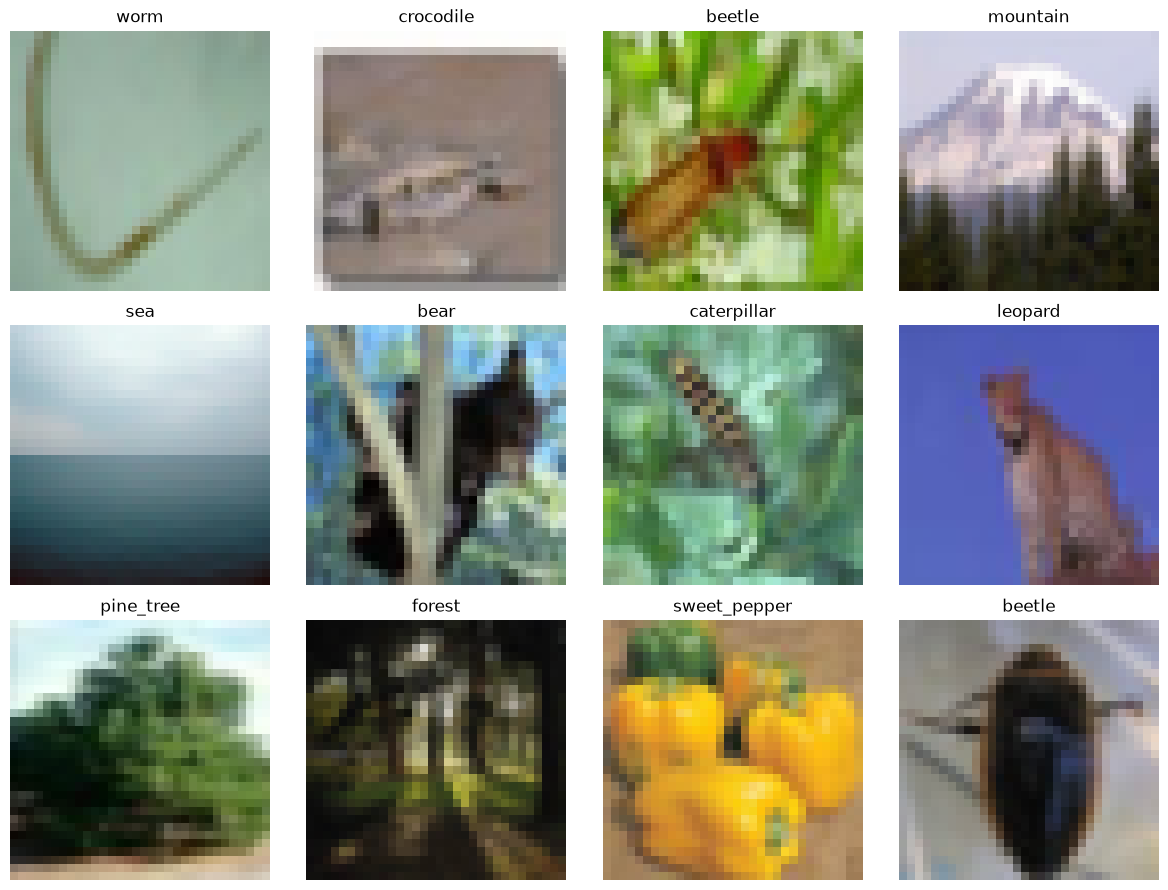

In [4]:

import matplotlib.pyplot as plt

# 將攤平的圖片還原為 32×32×3
images = X_train.reshape(-1, 3, 32, 32)
images = images.transpose(0, 2, 3, 1)

# 隨機選擇 12 張圖片
rng = np.random.default_rng(42)
indices = rng.choice(len(images), 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(images[idx])
    ax.set_title(class_names[y_train[idx]])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 確認 PyTorch 是否可以使用 GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("使用裝置：", device)
print("PyTorch 版本：", torch.__version__)

# 影像前處理
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 讀取訓練資料
train_dataset = datasets.CIFAR100(
    root=str(CIFAR_DIR),
    train=True,
    download=False,
    transform=transform
)

# 讀取測試資料
test_dataset = datasets.CIFAR100(
    root=str(CIFAR_DIR),
    train=False,
    download=False,
    transform=transform
)

# 建立 DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("訓練圖片數量：", len(train_dataset))
print("測試圖片數量：", len(test_dataset))
print("訓練 Batch 數量：", len(train_loader))
print("測試 Batch 數量：", len(test_loader))

# 取出一個 Batch
images_batch, labels_batch = next(iter(train_loader))

print("Images shape:", images_batch.shape)
print("Labels shape:", labels_batch.shape)


使用裝置： cuda
PyTorch 版本： 2.5.1+cu121
訓練圖片數量： 50000
測試圖片數量： 10000
訓練 Batch 數量： 1563
測試 Batch 數量： 313
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


In [6]:

import torch.nn as nn
from torchvision import models

# 載入 ImageNet 預訓練的 ResNet18
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# ResNet18 原本分類 1000 個類別
print("原始分類層：", model.fc)

# 修改成 CIFAR100 的 100 個類別
model.fc = nn.Linear(
    model.fc.in_features,
    100
)

# 將模型移到 GPU
model = model.to(device)

print("修改後分類層：", model.fc)
print("模型所在裝置：", next(model.parameters()).device)

# 計算模型參數量
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"模型參數量：{total_params:,}")


原始分類層： Linear(in_features=512, out_features=1000, bias=True)
修改後分類層： Linear(in_features=512, out_features=100, bias=True)
模型所在裝置： cuda:0
模型參數量：11,227,812


In [7]:

# 切換成推論模式
model.eval()

# 取出一個 Batch
images_batch, labels_batch = next(iter(train_loader))

# 將圖片移到 GPU
images_batch = images_batch.to(device)

# 不計算梯度，節省 GPU 記憶體
with torch.no_grad():
    outputs = model(images_batch)

print("輸入維度：", images_batch.shape)
print("輸出維度：", outputs.shape)

# 顯示第一張圖片的預測類別
predicted_class = outputs.argmax(dim=1)[0].item()

print("預測類別：", class_names[predicted_class])
print("真實類別：", class_names[labels_batch[0].item()])


輸入維度： torch.Size([32, 3, 224, 224])
輸出維度： torch.Size([32, 100])
預測類別： tulip
真實類別： cattle


In [16]:


import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torch.utils.data import DataLoader

# ========================================
# 1. 設定 GPU
# ========================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("使用裝置：", device)

# ========================================
# 2. 重新載入 ImageNet 預訓練模型
# ========================================
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# 將分類層修改為 CIFAR100 的 100 個類別
model.fc = nn.Linear(
    model.fc.in_features,
    100
)

# ========================================
# 3. 設定可訓練的網路層
# ========================================

# 先凍結所有參數
for param in model.parameters():
    param.requires_grad = False

# 解凍 layer3
for param in model.layer3.parameters():
    param.requires_grad = True

# 解凍 layer4
for param in model.layer4.parameters():
    param.requires_grad = True

# 解凍最後的分類層
for param in model.fc.parameters():
    param.requires_grad = True

# 模型移至 GPU
model = model.to(device)

# ========================================
# 4. 重新建立 DataLoader
# ========================================
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ========================================
# 5. 設定 Loss 與 Optimizer
# ========================================
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam([
    {
        "params": model.layer3.parameters(),
        "lr": 1e-5
    },
    {
        "params": model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": model.fc.parameters(),
        "lr": 1e-4
    }
])

# ========================================
# 6. 訓練參數
# ========================================
EPOCHS = 5

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"模型總參數量：{total_params:,}")
print(f"可訓練參數量：{trainable_params:,}")
print(f"Batch Size：{BATCH_SIZE}")
print(f"Epochs：{EPOCHS}")

# 顯示哪些層會參與訓練
print("\n各層訓練狀態：")

for name, param in model.named_parameters():
    if param.requires_grad:
        print("可訓練：", name)


使用裝置： cuda
模型總參數量：11,227,812
可訓練參數量：10,544,740
Batch Size：16
Epochs：5

各層訓練狀態：
可訓練： layer3.0.conv1.weight
可訓練： layer3.0.bn1.weight
可訓練： layer3.0.bn1.bias
可訓練： layer3.0.conv2.weight
可訓練： layer3.0.bn2.weight
可訓練： layer3.0.bn2.bias
可訓練： layer3.0.downsample.0.weight
可訓練： layer3.0.downsample.1.weight
可訓練： layer3.0.downsample.1.bias
可訓練： layer3.1.conv1.weight
可訓練： layer3.1.bn1.weight
可訓練： layer3.1.bn1.bias
可訓練： layer3.1.conv2.weight
可訓練： layer3.1.bn2.weight
可訓練： layer3.1.bn2.bias
可訓練： layer4.0.conv1.weight
可訓練： layer4.0.bn1.weight
可訓練： layer4.0.bn1.bias
可訓練： layer4.0.conv2.weight
可訓練： layer4.0.bn2.weight
可訓練： layer4.0.bn2.bias
可訓練： layer4.0.downsample.0.weight
可訓練： layer4.0.downsample.1.weight
可訓練： layer4.0.downsample.1.bias
可訓練： layer4.1.conv1.weight
可訓練： layer4.1.bn1.weight
可訓練： layer4.1.bn1.bias
可訓練： layer4.1.conv2.weight
可訓練： layer4.1.bn2.weight
可訓練： layer4.1.bn2.bias
可訓練： fc.weight
可訓練： fc.bias


In [17]:

from tqdm.auto import tqdm
from pathlib import Path
import torch
import torch.nn as nn
import time

# ========================================
# 1. 訓練設定
# ========================================
train_losses = []
train_accuracies = []
test_accuracies = []

best_acc = 0.0

SAVE_PATH = WEEK5_DIR / "resnet18_cifar100_best.pth"

# 是否使用 AMP
USE_AMP = (device.type == "cuda")

# GradScaler 避免 FP16 梯度數值過小
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Device:", device)
print("AMP Enabled:", USE_AMP)
print("Batch Size:", train_loader.batch_size)
print("Epochs:", EPOCHS)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ========================================
# 2. 開始訓練
# ========================================
for epoch in range(EPOCHS):

    start_time = time.time()

    model.train()

    # 固定 BatchNorm running statistics
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    # ====================================
    # 3. Training
    # ====================================
    for batch_images, batch_labels in progress:

        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        batch_labels = batch_labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # AMP Forward
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

        # AMP Backward
        scaler.scale(loss).backward()

        # 更新參數
        scaler.step(optimizer)
        scaler.update()

        running_loss += (
            loss.item() * batch_images.size(0)
        )

        predicted = outputs.argmax(dim=1)

        correct += (
            predicted == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    # ====================================
    # 4. Testing
    # ====================================
    model.eval()

    test_correct = 0
    test_total = 0

    with torch.inference_mode():

        for batch_images, batch_labels in test_loader:

            batch_images = batch_images.to(
                device,
                non_blocking=True
            )

            batch_labels = batch_labels.to(
                device,
                non_blocking=True
            )

            # 測試階段也使用 AMP
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(batch_images)

            predicted = outputs.argmax(dim=1)

            test_correct += (
                predicted == batch_labels
            ).sum().item()

            test_total += batch_labels.size(0)

    test_acc = 100 * test_correct / test_total
    test_accuracies.append(test_acc)

    # ====================================
    # 5. 儲存最佳模型
    # ====================================
    if test_acc > best_acc:

        best_acc = test_acc

        torch.save(
            model.state_dict(),
            SAVE_PATH
        )

        print(
            f"Best model saved! "
            f"Accuracy: {best_acc:.2f}%"
        )

    # ====================================
    # 6. 顯示 Epoch 結果
    # ====================================
    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

    # 顯示 GPU 記憶體使用量
    if torch.cuda.is_available():

        peak_memory = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        print(
            f"Peak GPU Memory: "
            f"{peak_memory:.2f} GB"
        )

        torch.cuda.reset_peak_memory_stats()

print("\nTraining Completed!")
print(f"Best Test Accuracy: {best_acc:.2f}%")
print(f"Model saved to: {SAVE_PATH}")


Device: cuda
AMP Enabled: True
Batch Size: 16
Epochs: 5
GPU: NVIDIA GeForce RTX 2060


Epoch 1/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Best model saved! Accuracy: 68.68%
Epoch 1/5 | Loss: 1.6385 | Train Acc: 55.23% | Test Acc: 68.68% | Time: 125.7s
Peak GPU Memory: 0.33 GB


Epoch 2/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Best model saved! Accuracy: 73.35%
Epoch 2/5 | Loss: 0.8472 | Train Acc: 74.47% | Test Acc: 73.35% | Time: 126.6s
Peak GPU Memory: 0.33 GB


...

Best model saved! Accuracy: 75.08%
Epoch 3/5 | Loss: 0.6308 | Train Acc: 80.45% | Test Acc: 75.08% | Time: 121.6s
Peak GPU Memory: 0.33 GB


Epoch 4/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Best model saved! Accuracy: 75.53%
Epoch 4/5 | Loss: 0.4802 | Train Acc: 84.88% | Test Acc: 75.53% | Time: 121.6s
Peak GPU Memory: 0.33 GB


Epoch 5/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Best model saved! Accuracy: 76.05%
Epoch 5/5 | Loss: 0.3604 | Train Acc: 88.62% | Test Acc: 76.05% | Time: 121.0s
Peak GPU Memory: 0.33 GB

Training Completed!
Best Test Accuracy: 76.05%
Model saved to: D:\project\MMIP\week5\resnet18_cifar100_best.pth


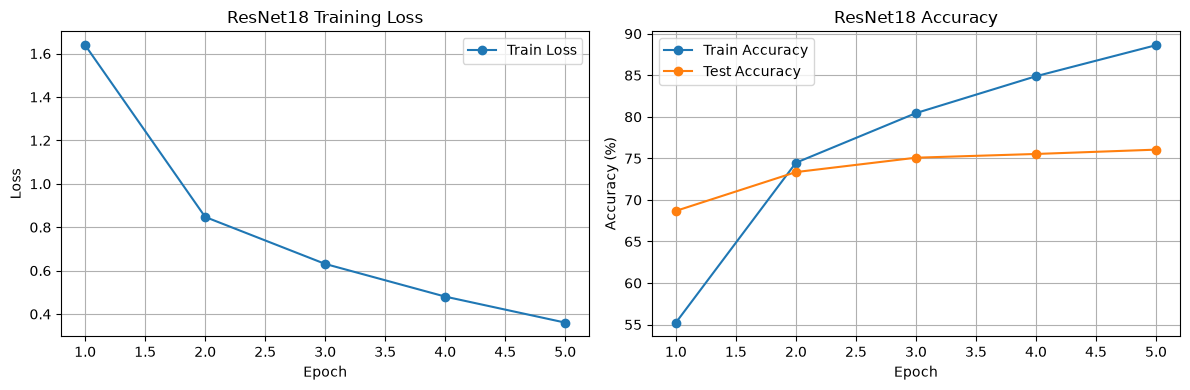

In [18]:

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training Loss
axes[0].plot(
    epochs,
    train_losses,
    marker="o",
    label="Train Loss"
)

axes[0].set_title("ResNet18 Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)
axes[0].legend()

# Accuracy
axes[1].plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    test_accuracies,
    marker="o",
    label="Test Accuracy"
)

axes[1].set_title("ResNet18 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


In [19]:

import torch
import torch.nn as nn

# 載入最佳模型
model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# 移除最後分類層，保留 512 維特徵
feature_extractor = nn.Sequential(
    *list(model.children())[:-1],
    nn.Flatten()
).to(device)

feature_extractor.eval()

# 測試 Feature Extractor
sample_images, sample_labels = next(iter(test_loader))

with torch.inference_mode():
    features = feature_extractor(
        sample_images.to(device)
    )

print("Input Shape:", sample_images.shape)
print("Feature Shape:", features.shape)


Input Shape: torch.Size([16, 3, 224, 224])
Feature Shape: torch.Size([16, 512])


In [20]:

import torch
import torch.nn as nn

# 載入最佳模型
model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# 移除最後分類層，保留 512 維特徵
feature_extractor = nn.Sequential(
    *list(model.children())[:-1],
    nn.Flatten()
).to(device)

feature_extractor.eval()

# 測試 Feature Extractor
sample_images, sample_labels = next(iter(test_loader))

with torch.inference_mode():
    features = feature_extractor(
        sample_images.to(device)
    )

print("Input Shape:", sample_images.shape)
print("Feature Shape:", features.shape)


Input Shape: torch.Size([16, 3, 224, 224])
Feature Shape: torch.Size([16, 512])


In [21]:

from torch.utils.data import Subset, DataLoader
import torch.nn.functional as F
from tqdm.auto import tqdm

# ========================================
# 1. 建立 Gallery Dataset
# ========================================

GALLERY_SIZE = 2000

gallery_dataset = Subset(
    test_dataset,
    range(GALLERY_SIZE)
)

gallery_loader = DataLoader(
    gallery_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# ========================================
# 2. 提取影像特徵
# ========================================

gallery_features = []
gallery_labels = []

feature_extractor.eval()

with torch.inference_mode():

    for batch_images, batch_labels in tqdm(
        gallery_loader,
        desc="Extracting Gallery Features"
    ):

        batch_images = batch_images.to(device)

        # CNN 提取 512 維特徵
        features = feature_extractor(batch_images)

        # L2 Normalization
        features = F.normalize(
            features,
            p=2,
            dim=1
        )

        gallery_features.append(
            features.cpu()
        )

        gallery_labels.append(
            batch_labels.cpu()
        )

# ========================================
# 3. 合併所有 Batch
# ========================================

gallery_features = torch.cat(
    gallery_features,
    dim=0
)

gallery_labels = torch.cat(
    gallery_labels,
    dim=0
)

print("Gallery Features Shape:", gallery_features.shape)
print("Gallery Labels Shape:", gallery_labels.shape)


Extracting Gallery Features:   0%|          | 0/63 [00:00<?, ?it/s]

Gallery Features Shape: torch.Size([2000, 512])
Gallery Labels Shape: torch.Size([2000])


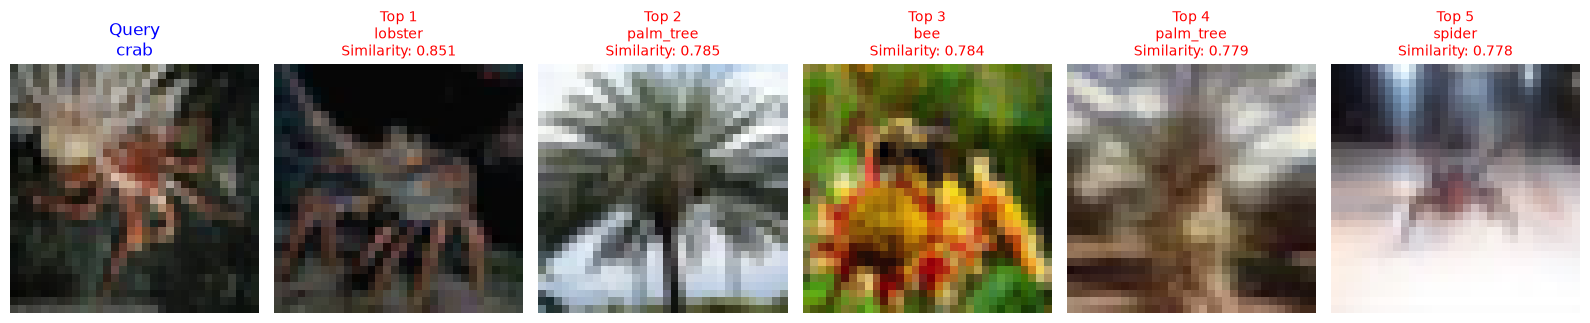

Query Class: crab
Correct Retrieved: 0/5
Precision@5: 0.00%


In [22]:

import numpy as np
import matplotlib.pyplot as plt

# ========================================
# 1. 準備原始測試影像
# ========================================

raw_test_images = X_test.reshape(
    -1, 3, 32, 32
).transpose(0, 2, 3, 1)

# ========================================
# 2. 選擇 Query Image
# ========================================

query_idx = 100
top_k = 5

query_feature = gallery_features[query_idx]
query_label = gallery_labels[query_idx].item()

# ========================================
# 3. 計算 Cosine Similarity
# ========================================

similarities = gallery_features @ query_feature

# 排除 Query 自己
similarities[query_idx] = -float("inf")

# 找出相似度最高的 5 張
top_values, top_indices = torch.topk(
    similarities,
    k=top_k
)

# ========================================
# 4. 顯示檢索結果
# ========================================

fig, axes = plt.subplots(
    1, top_k + 1,
    figsize=(16, 3.5)
)

# Query Image
axes[0].imshow(raw_test_images[query_idx])
axes[0].set_title(
    f"Query\n{class_names[query_label]}",
    color="blue"
)
axes[0].axis("off")

correct_count = 0

# Retrieved Images
for i, (idx, score) in enumerate(
    zip(top_indices, top_values)
):

    idx = idx.item()
    score = score.item()

    retrieved_label = gallery_labels[idx].item()

    is_correct = (retrieved_label == query_label)

    if is_correct:
        correct_count += 1

    axes[i + 1].imshow(raw_test_images[idx])

    axes[i + 1].set_title(
        f"Top {i+1}\n"
        f"{class_names[retrieved_label]}\n"
        f"Similarity: {score:.3f}",
        color="green" if is_correct else "red",
        fontsize=10
    )

    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

# ========================================
# 5. 計算 Precision@5
# ========================================

precision_at_5 = correct_count / top_k

print("Query Class:", class_names[query_label])
print(f"Correct Retrieved: {correct_count}/{top_k}")
print(f"Precision@5: {precision_at_5:.2%}")


In [23]:

import torch
import torch.nn.functional as F

# ========================================
# 1. 取得正規化後的特徵
# ========================================

features = F.normalize(
    gallery_features.float(),
    p=2,
    dim=1
)

labels = gallery_labels

# ========================================
# 2. 計算所有影像的相似度
# ========================================

similarity_matrix = features @ features.T

# 排除自己與自己的比對
similarity_matrix.fill_diagonal_(
    -float("inf")
)

# ========================================
# 3. 取得每張 Query 的 Top-5
# ========================================

top_k = 5

top_indices = torch.topk(
    similarity_matrix,
    k=top_k,
    dim=1
).indices

retrieved_labels = labels[top_indices]

# 判斷檢索結果是否與 Query 同類別
correct = (
    retrieved_labels == labels.unsqueeze(1)
)

# ========================================
# 4. 計算 Mean Precision@5
# ========================================

precision_per_query = correct.float().mean(dim=1)

mean_precision = precision_per_query.mean().item()

print(f"Query 數量：{len(labels)}")
print(f"Mean Precision@5：{mean_precision:.2%}")

# ========================================
# 5. 統計不同 Precision@5 的 Query 數量
# ========================================

for score in [0, 0.2, 0.4, 0.6, 0.8, 1.0]:

    count = torch.isclose(
        precision_per_query,
        torch.tensor(
            score,
            dtype=precision_per_query.dtype
        )
    ).sum().item()

    print(
        f"Precision@5 = {score:.0%}: "
        f"{count} 張"
    )

# ========================================
# 6. 與 Fine-tuning 前比較
# ========================================

baseline_precision = 0.2914

difference = mean_precision - baseline_precision

print("\n===== Fine-tuning 效果比較 =====")
print(f"Before Fine-tuning：{baseline_precision:.2%}")
print(f"After Fine-tuning ：{mean_precision:.2%}")
print(f"Difference        ：{difference * 100:+.2f} 個百分點")


Query 數量：2000
Mean Precision@5：49.86%
Precision@5 = 0%: 344 張
Precision@5 = 20%: 328 張
Precision@5 = 40%: 341 張
Precision@5 = 60%: 328 張
Precision@5 = 80%: 303 張
Precision@5 = 100%: 356 張

===== Fine-tuning 效果比較 =====
Before Fine-tuning：29.14%
After Fine-tuning ：49.86%
Difference        ：+20.72 個百分點


In [24]:

import pandas as pd

cnn_results = pd.DataFrame([
    {
        "Model": "ResNet18",
        "Training": "FC Only",
        "Test Accuracy (%)": 66.60,
        "Mean Precision@5 (%)": 29.14
    },
    {
        "Model": "ResNet18",
        "Training": "Fine-tuning Layer3+Layer4+FC",
        "Test Accuracy (%)": 76.05,
        "Mean Precision@5 (%)": 49.86
    }
])

display(cnn_results)

# 儲存結果
csv_path = WEEK5_DIR / "quiz1_cnn_results.csv"

cnn_results.to_csv(
    csv_path,
    index=False
)

print("Results saved to:", csv_path)


,Model,Training,Test Accuracy (%),Mean Precision@5 (%)
0,ResNet18,FC Only,66.60,29.14
1,ResNet18,Fine-tuning Layer3+Layer4+FC,76.05,49.86


Results saved to: D:\project\MMIP\week5\quiz1_cnn_results.csv


In [25]:

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# ========================================
# 1. 載入預訓練 ViT
# ========================================

vit_weights = models.ViT_B_16_Weights.DEFAULT

vit_model = models.vit_b_16(
    weights=vit_weights
)

# ========================================
# 2. 修改分類層為 CIFAR100
# ========================================

vit_model.heads.head = nn.Linear(
    vit_model.heads.head.in_features,
    100
)

# ========================================
# 3. 凍結所有參數
# ========================================

for param in vit_model.parameters():
    param.requires_grad = False

# ========================================
# 4. 解凍最後一個 Transformer Block
# ========================================

for param in vit_model.encoder.layers[-1].parameters():
    param.requires_grad = True

# 解凍 Encoder 最後的 LayerNorm
for param in vit_model.encoder.ln.parameters():
    param.requires_grad = True

# 解凍分類層
for param in vit_model.heads.parameters():
    param.requires_grad = True

# ========================================
# 5. 將模型移至 GPU
# ========================================

vit_model = vit_model.to(device)

# ========================================
# 6. 設定 Loss 和 Optimizer
# ========================================

vit_criterion = nn.CrossEntropyLoss()

vit_optimizer = optim.AdamW([
    {
        "params": vit_model.encoder.layers[-1].parameters(),
        "lr": 1e-5
    },
    {
        "params": vit_model.encoder.ln.parameters(),
        "lr": 1e-5
    },
    {
        "params": vit_model.heads.parameters(),
        "lr": 1e-4
    }
], weight_decay=0.01)

VIT_EPOCHS = 5

# ========================================
# 7. 顯示模型資訊
# ========================================

vit_total_params = sum(
    p.numel() for p in vit_model.parameters()
)

vit_trainable_params = sum(
    p.numel() for p in vit_model.parameters()
    if p.requires_grad
)

print("Device:", device)
print("ViT Total Parameters:", f"{vit_total_params:,}")
print("ViT Trainable Parameters:", f"{vit_trainable_params:,}")
print("Epochs:", VIT_EPOCHS)

print("\nTrainable Layers:")

for name, param in vit_model.named_parameters():
    if param.requires_grad:
        print(name)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\user/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth
100%|██████████| 330M/330M [00:34<00:00, 10.0MB/s] 


Device: cuda
ViT Total Parameters: 85,875,556
ViT Trainable Parameters: 7,166,308
Epochs: 5

Trainable Layers:
encoder.layers.encoder_layer_11.ln_1.weight
encoder.layers.encoder_layer_11.ln_1.bias
encoder.layers.encoder_layer_11.self_attention.in_proj_weight
encoder.layers.encoder_layer_11.self_attention.in_proj_bias
encoder.layers.encoder_layer_11.self_attention.out_proj.weight
encoder.layers.encoder_layer_11.self_attention.out_proj.bias
encoder.layers.encoder_layer_11.ln_2.weight
encoder.layers.encoder_layer_11.ln_2.bias
encoder.layers.encoder_layer_11.mlp.0.weight
encoder.layers.encoder_layer_11.mlp.0.bias
encoder.layers.encoder_layer_11.mlp.3.weight
encoder.layers.encoder_layer_11.mlp.3.bias
encoder.ln.weight
encoder.ln.bias
heads.head.weight
heads.head.bias


In [26]:

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from pathlib import Path
import torch
import time

# ========================================
# 1. 建立 ViT DataLoader
# ========================================

VIT_BATCH_SIZE = 8

vit_train_loader = DataLoader(
    train_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

vit_test_loader = DataLoader(
    test_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ========================================
# 2. AMP 設定
# ========================================

vit_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# ========================================
# 3. 訓練紀錄
# ========================================

vit_train_losses = []
vit_train_accuracies = []
vit_test_accuracies = []

vit_best_acc = 0.0

VIT_SAVE_PATH = WEEK5_DIR / "vit_b16_cifar100_best.pth"

print("GPU:", torch.cuda.get_device_name(0))
print("ViT Batch Size:", VIT_BATCH_SIZE)
print("ViT Epochs:", VIT_EPOCHS)

# ========================================
# 4. 開始訓練
# ========================================

for epoch in range(VIT_EPOCHS):

    start_time = time.time()

    vit_model.train()

    # 凍結的 Encoder Blocks 不使用訓練模式
    for layer in vit_model.encoder.layers[:-1]:
        layer.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        vit_train_loader,
        desc=f"ViT Epoch {epoch+1}/{VIT_EPOCHS}"
    )

    # ====================================
    # 5. Training
    # ====================================

    for batch_images, batch_labels in progress:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        vit_optimizer.zero_grad(set_to_none=True)

        # AMP Forward
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = vit_model(batch_images)
            loss = vit_criterion(outputs, batch_labels)

        # AMP Backward
        vit_scaler.scale(loss).backward()

        # 更新參數
        vit_scaler.step(vit_optimizer)
        vit_scaler.update()

        running_loss += loss.item() * batch_images.size(0)

        predicted = outputs.argmax(dim=1)

        correct += (
            predicted == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    vit_train_losses.append(epoch_loss)
    vit_train_accuracies.append(epoch_acc)

    # ====================================
    # 6. Testing
    # ====================================

    vit_model.eval()

    test_correct = 0
    test_total = 0

    with torch.inference_mode():

        for batch_images, batch_labels in vit_test_loader:

            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = vit_model(batch_images)

            predicted = outputs.argmax(dim=1)

            test_correct += (
                predicted == batch_labels
            ).sum().item()

            test_total += batch_labels.size(0)

    test_acc = 100 * test_correct / test_total

    vit_test_accuracies.append(test_acc)

    # ====================================
    # 7. 儲存最佳 ViT
    # ====================================

    if test_acc > vit_best_acc:

        vit_best_acc = test_acc

        torch.save(
            vit_model.state_dict(),
            VIT_SAVE_PATH
        )

        print(
            f"Best ViT saved! "
            f"Accuracy: {vit_best_acc:.2f}%"
        )

    elapsed = time.time() - start_time

    print(
        f"ViT Epoch {epoch+1}/{VIT_EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

    if torch.cuda.is_available():

        peak_memory = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        print(
            f"Peak GPU Memory: {peak_memory:.2f} GB"
        )

        torch.cuda.reset_peak_memory_stats()

print("\nViT Training Completed!")
print(f"Best ViT Test Accuracy: {vit_best_acc:.2f}%")
print(f"Model saved to: {VIT_SAVE_PATH}")


GPU: NVIDIA GeForce RTX 2060
ViT Batch Size: 8
ViT Epochs: 5


ViT Epoch 1/5:   0%|          | 0/6250 [00:00<?, ?it/s]

Best ViT saved! Accuracy: 78.70%
ViT Epoch 1/5 | Loss: 1.2804 | Train Acc: 70.30% | Test Acc: 78.70% | Time: 478.6s
Peak GPU Memory: 0.67 GB


ViT Epoch 2/5:   0%|          | 0/6250 [00:00<?, ?it/s]

Best ViT saved! Accuracy: 80.79%
ViT Epoch 2/5 | Loss: 0.6030 | Train Acc: 81.95% | Test Acc: 80.79% | Time: 493.1s
Peak GPU Memory: 0.67 GB


...

Best ViT saved! Accuracy: 82.31%
ViT Epoch 3/5 | Loss: 0.4746 | Train Acc: 85.74% | Test Acc: 82.31% | Time: 461.0s
Peak GPU Memory: 0.67 GB


ViT Epoch 4/5:   0%|          | 0/6250 [00:00<?, ?it/s]

Best ViT saved! Accuracy: 82.89%
ViT Epoch 4/5 | Loss: 0.3873 | Train Acc: 88.42% | Test Acc: 82.89% | Time: 467.2s
Peak GPU Memory: 0.67 GB


ViT Epoch 5/5:   0%|          | 0/6250 [00:00<?, ?it/s]

ViT Epoch 5/5 | Loss: 0.3167 | Train Acc: 90.66% | Test Acc: 82.81% | Time: 466.8s
Peak GPU Memory: 0.67 GB

ViT Training Completed!
Best ViT Test Accuracy: 82.89%
Model saved to: D:\project\MMIP\week5\vit_b16_cifar100_best.pth


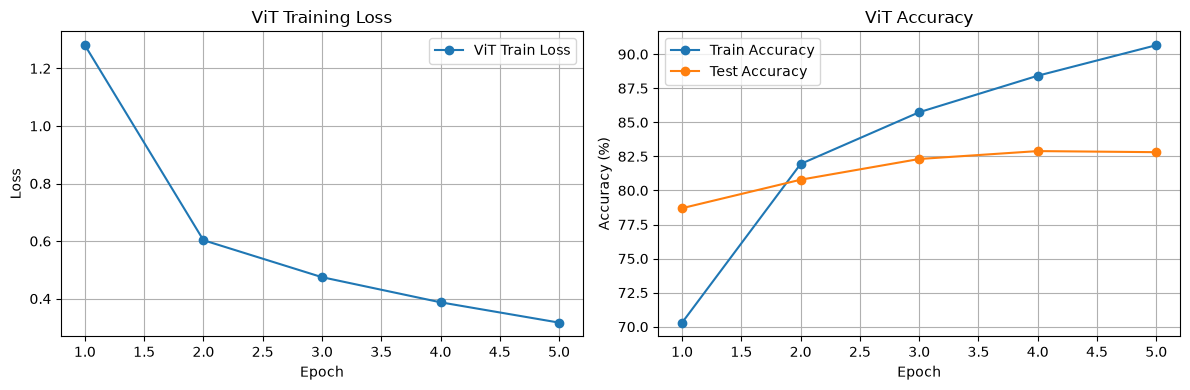

In [27]:

import matplotlib.pyplot as plt

epochs = range(1, len(vit_train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(
    epochs,
    vit_train_losses,
    marker="o",
    label="ViT Train Loss"
)
axes[0].set_title("ViT Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)
axes[0].legend()

# Accuracy
axes[1].plot(
    epochs,
    vit_train_accuracies,
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs,
    vit_test_accuracies,
    marker="o",
    label="Test Accuracy"
)
axes[1].set_title("ViT Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


In [28]:

import torch
import torch.nn as nn

# ========================================
# 1. 載入最佳 ViT 權重
# ========================================

vit_model.load_state_dict(
    torch.load(
        VIT_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

vit_model.eval()

# ========================================
# 2. 建立 ViT Feature Extractor
# ========================================

class ViTFeatureExtractor(nn.Module):

    def __init__(self, vit):
        super().__init__()
        self.vit = vit

    def forward(self, x):

        # Patch Embedding + Position Encoding
        x = self.vit._process_input(x)

        batch_size = x.shape[0]

        # 加入 Class Token
        class_token = self.vit.class_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat(
            [class_token, x],
            dim=1
        )

        # Transformer Encoder
        x = self.vit.encoder(x)

        # 取出 Class Token
        features = x[:, 0]

        return features

vit_feature_extractor = ViTFeatureExtractor(
    vit_model
).to(device)

vit_feature_extractor.eval()

# ========================================
# 3. 測試特徵維度
# ========================================

sample_images, _ = next(iter(vit_test_loader))

with torch.inference_mode():

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):

        features = vit_feature_extractor(
            sample_images.to(device)
        )

print("Input Shape:", sample_images.shape)
print("Feature Shape:", features.shape)


Input Shape: torch.Size([8, 3, 224, 224])
Feature Shape: torch.Size([8, 768])


In [29]:

from torch.utils.data import Subset, DataLoader
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F

# ========================================
# 1. 建立 ViT Gallery
# ========================================

VIT_GALLERY_SIZE = 2000

vit_gallery_dataset = Subset(
    test_dataset,
    range(VIT_GALLERY_SIZE)
)

vit_gallery_loader = DataLoader(
    vit_gallery_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# ========================================
# 2. 提取 ViT 特徵
# ========================================

vit_gallery_features = []
vit_gallery_labels = []

vit_feature_extractor.eval()

with torch.inference_mode():

    for batch_images, batch_labels in tqdm(
        vit_gallery_loader,
        desc="Extracting ViT Gallery Features"
    ):

        batch_images = batch_images.to(device)

        # 使用 AMP 加速
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            features = vit_feature_extractor(
                batch_images
            )

        # 轉為 float32，再做 L2 Normalization
        features = F.normalize(
            features.float(),
            p=2,
            dim=1
        )

        vit_gallery_features.append(
            features.cpu()
        )

        vit_gallery_labels.append(
            batch_labels.cpu()
        )

# ========================================
# 3. 合併所有 Batch
# ========================================

vit_gallery_features = torch.cat(
    vit_gallery_features,
    dim=0
)

vit_gallery_labels = torch.cat(
    vit_gallery_labels,
    dim=0
)

print(
    "ViT Gallery Features Shape:",
    vit_gallery_features.shape
)

print(
    "ViT Gallery Labels Shape:",
    vit_gallery_labels.shape
)

# 確認 CNN 與 ViT 使用相同的 Gallery
print(
    "Same Gallery Labels:",
    torch.equal(
        gallery_labels,
        vit_gallery_labels
    )
)


Extracting ViT Gallery Features:   0%|          | 0/250 [00:00<?, ?it/s]

ViT Gallery Features Shape: torch.Size([2000, 768])
ViT Gallery Labels Shape: torch.Size([2000])
Same Gallery Labels: True


In [30]:

import torch
import torch.nn.functional as F

# ========================================
# 1. 正規化 ViT 特徵
# ========================================

features = F.normalize(
    vit_gallery_features.float(),
    p=2,
    dim=1
)

labels = vit_gallery_labels

# ========================================
# 2. 計算 Cosine Similarity
# ========================================

similarity_matrix = features @ features.T

# 排除 Query 自己
similarity_matrix.fill_diagonal_(
    -float("inf")
)

# ========================================
# 3. 找出每張 Query 的 Top-5
# ========================================

top_k = 5

top_indices = torch.topk(
    similarity_matrix,
    k=top_k,
    dim=1
).indices

retrieved_labels = labels[top_indices]

# 判斷是否屬於相同類別
correct = (
    retrieved_labels == labels.unsqueeze(1)
)

# ========================================
# 4. 計算 Mean Precision@5
# ========================================

vit_precision_per_query = correct.float().mean(dim=1)

vit_mean_precision = (
    vit_precision_per_query.mean().item()
)

print(f"Query 數量：{len(labels)}")
print(f"ViT Mean Precision@5：{vit_mean_precision:.2%}")

# ========================================
# 5. 統計不同 Precision@5 的數量
# ========================================

for score in [0, 0.2, 0.4, 0.6, 0.8, 1.0]:

    count = torch.isclose(
        vit_precision_per_query,
        torch.tensor(
            score,
            dtype=vit_precision_per_query.dtype
        )
    ).sum().item()

    print(
        f"Precision@5 = {score:.0%}: "
        f"{count} 張"
    )

# ========================================
# 6. CNN vs ViT 比較
# ========================================

cnn_mean_precision = 0.4986

difference = (
    vit_mean_precision - cnn_mean_precision
) * 100

print("\n===== CNN vs ViT =====")
print(f"ResNet18 Mean Precision@5：{cnn_mean_precision:.2%}")
print(f"ViT-B/16 Mean Precision@5：{vit_mean_precision:.2%}")
print(f"Difference：{difference:+.2f} 個百分點")


Query 數量：2000
ViT Mean Precision@5：64.04%
Precision@5 = 0%: 225 張
Precision@5 = 20%: 225 張
Precision@5 = 40%: 241 張
Precision@5 = 60%: 261 張
Precision@5 = 80%: 326 張
Precision@5 = 100%: 722 張

===== CNN vs ViT =====
ResNet18 Mean Precision@5：49.86%
ViT-B/16 Mean Precision@5：64.04%
Difference：+14.18 個百分點


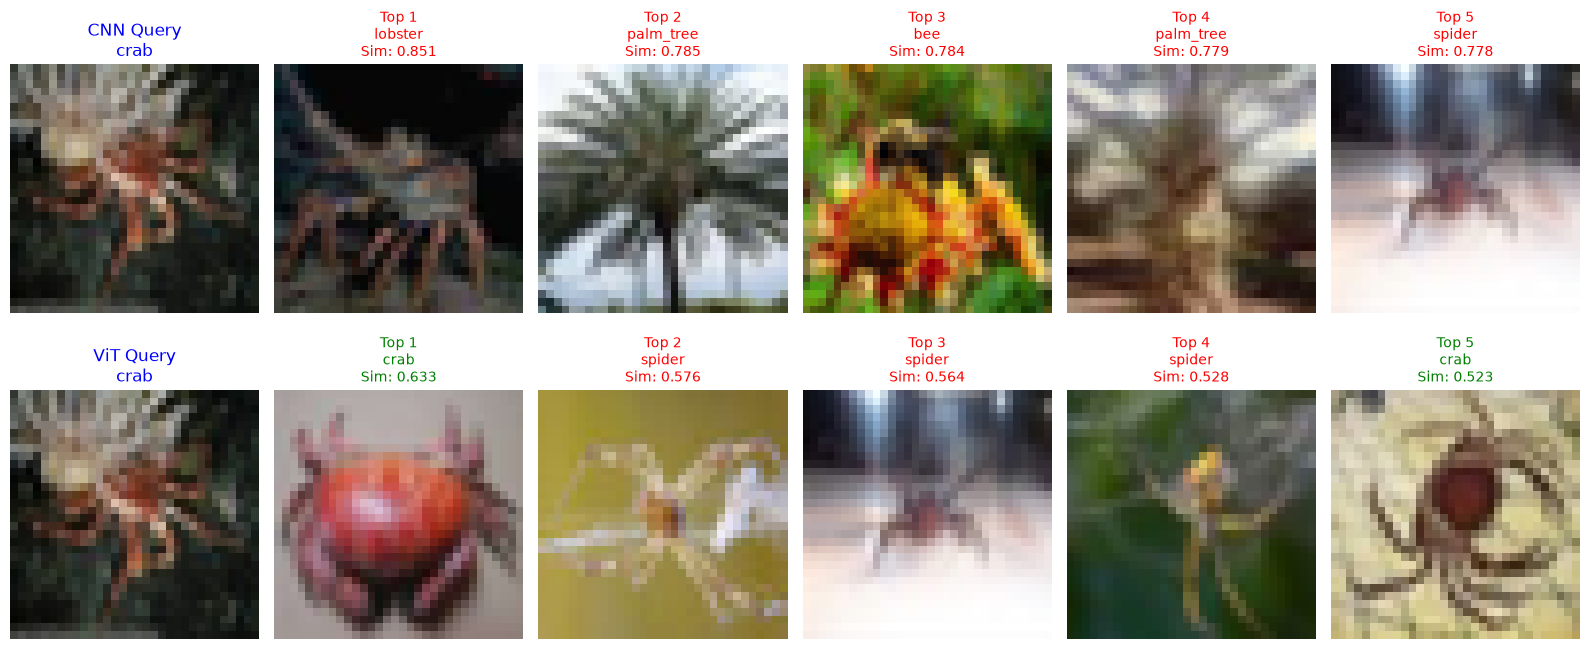

Query: crab
CNN Precision@5: 0.00%
ViT Precision@5: 40.00%


In [31]:

import matplotlib.pyplot as plt
import torch

# ========================================
# 1. 選擇 Query
# ========================================

query_idx = 100
top_k = 5

query_label = gallery_labels[query_idx].item()

# ========================================
# 2. CNN 檢索
# ========================================

cnn_similarities = (
    gallery_features @ gallery_features[query_idx]
).clone()

cnn_similarities[query_idx] = -float("inf")

cnn_scores, cnn_indices = torch.topk(
    cnn_similarities,
    k=top_k
)

# ========================================
# 3. ViT 檢索
# ========================================

vit_similarities = (
    vit_gallery_features @ vit_gallery_features[query_idx]
).clone()

vit_similarities[query_idx] = -float("inf")

vit_scores, vit_indices = torch.topk(
    vit_similarities,
    k=top_k
)

# ========================================
# 4. 畫出比較圖
# ========================================

fig, axes = plt.subplots(
    2, top_k + 1,
    figsize=(16, 7)
)

cnn_correct = 0
vit_correct = 0

for row, (model_name, indices, scores, labels) in enumerate([
    ("CNN", cnn_indices, cnn_scores, gallery_labels),
    ("ViT", vit_indices, vit_scores, vit_gallery_labels)
]):

    # Query Image
    axes[row, 0].imshow(raw_test_images[query_idx])
    axes[row, 0].set_title(
        f"{model_name} Query\n{class_names[query_label]}",
        color="blue"
    )
    axes[row, 0].axis("off")

    # Top-5
    for i in range(top_k):

        idx = indices[i].item()
        score = scores[i].item()

        retrieved_label = labels[idx].item()
        is_correct = (retrieved_label == query_label)

        if is_correct:
            if row == 0:
                cnn_correct += 1
            else:
                vit_correct += 1

        axes[row, i + 1].imshow(raw_test_images[idx])
        axes[row, i + 1].set_title(
            f"Top {i+1}\n"
            f"{class_names[retrieved_label]}\n"
            f"Sim: {score:.3f}",
            color="green" if is_correct else "red",
            fontsize=10
        )
        axes[row, i + 1].axis("off")

plt.tight_layout()
plt.show()

print("Query:", class_names[query_label])
print(f"CNN Precision@5: {cnn_correct/top_k:.2%}")
print(f"ViT Precision@5: {vit_correct/top_k:.2%}")


### Quiz 1 — Experimental Results and Discussion

In this experiment, we implemented an image retrieval system using the CIFAR100 dataset and compared two pretrained backbones: ResNet18 (CNN) and ViT-B/16 (Vision Transformer).

Both models were fine-tuned on CIFAR100, and image embeddings were extracted for similarity-based retrieval. Cosine similarity was used to retrieve the top five most similar images from a gallery containing 2,000 images.

| Model | Classification Accuracy | Mean Precision@5 |
|---|---:|---:|
| ResNet18 (FC only) | 66.60% | 29.14% |
| ResNet18 (Fine-tuned) | 76.05% | 49.86% |
| ViT-B/16 (Fine-tuned) | **82.89%** | **64.04%** |

Fine-tuning improved ResNet18's Mean Precision@5 from 29.14% to 49.86%, demonstrating that adapting the feature extractor to CIFAR100 can improve image retrieval performance.

ViT-B/16 achieved the highest Mean Precision@5 of 64.04%, outperforming the fine-tuned ResNet18 by 14.18 percentage points.

In the crab image retrieval example, ResNet18 achieved 0% Precision@5, while ViT-B/16 achieved 40%, retrieving two images from the correct class.

These results suggest that ViT-B/16 produced more effective image representations for this retrieval setup. However, ViT-B/16 required more parameters and longer training time than ResNet18.

**Limitations:** The experiments used different fine-tuning configurations for the two backbones. Additionally, the same 2,000 test images served as queries and gallery images, with self-matches excluded. Model checkpoints were selected using test accuracy rather than a separate validation set. Therefore, the results should be interpreted as a preliminary comparison rather than a fully controlled benchmark.

# Quiz 2: Multimodal Image + Text Classification

In [32]:

from pathlib import Path

# Week 5 資料夾
WEEK5_DIR = Path(r"D:\project\MMIP\week5")

# Flickr30k 資料集
FLICKR_DIR = WEEK5_DIR / "data" / "Flickr30k"

print("Flickr30k 路徑：", FLICKR_DIR)
print("資料夾是否存在：", FLICKR_DIR.exists())

# 顯示第一層檔案與資料夾
if FLICKR_DIR.exists():

    for item in sorted(FLICKR_DIR.iterdir()):
        if item.is_dir():
            print("[資料夾]", item.name)
        else:
            print("[檔案]", item.name)
else:
    print("找不到 Flickr30k 資料集！")


Flickr30k 路徑： D:\project\MMIP\week5\data\Flickr30k
資料夾是否存在： True
[資料夾] .cache
[檔案] .gitattributes
[資料夾] cache
[檔案] flickr30k-images.zip
[檔案] flickr30k.py
[檔案] flickr_annotations_30k.csv
[檔案] README.md


In [33]:

import pandas as pd

# CSV 檔案路徑
ANNOTATION_PATH = (
    FLICKR_DIR / "flickr_annotations_30k.csv"
)

# 讀取 CSV
df = pd.read_csv(ANNOTATION_PATH)

# 顯示資料基本資訊
print("資料筆數：", len(df))
print("\n欄位名稱：")
print(df.columns.tolist())

print("\n前 5 筆資料：")
display(df.head())

print("\n各欄位缺失值數量：")
print(df.isnull().sum())


資料筆數： 31014

欄位名稱：
['raw', 'sentids', 'split', 'filename', 'img_id']

前 5 筆資料：


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2
3,"[""Someone in a blue shirt and hat is standing ...","[15, 16, 17, 18, 19]",train,1000344755.jpg,3
4,"[""Two men, one in a gray shirt, one in a black...","[20, 21, 22, 23, 24]",train,1000366164.jpg,4



各欄位缺失值數量：
raw         0
sentids     0
split       0
filename    0
img_id      0
dtype: int64


In [34]:

import ast

# ========================================
# 1. 將 raw 字串轉成 Python List
# ========================================

def parse_captions(value):
    if isinstance(value, list):
        return value

    return ast.literal_eval(value)

df["captions"] = df["raw"].apply(parse_captions)

# ========================================
# 2. 顯示第一張圖片的 Captions
# ========================================

print("Image:", df.iloc[0]["filename"])
print("\nCaptions:")

for i, caption in enumerate(df.iloc[0]["captions"]):
    print(f"{i+1}. {caption}")

# ========================================
# 3. 統計每張圖片的 Caption 數量
# ========================================

df["caption_count"] = df["captions"].apply(len)

print("\nCaption 數量統計：")
print(df["caption_count"].value_counts().sort_index())

# ========================================
# 4. 統計 Dataset Split
# ========================================

print("\nDataset Split：")
print(df["split"].value_counts())


Image: 1000092795.jpg

Captions:
1. Two young guys with shaggy hair look at their hands while hanging out in the yard.
2. Two young, White males are outside near many bushes.
3. Two men in green shirts are standing in a yard.
4. A man in a blue shirt standing in a garden.
5. Two friends enjoy time spent together.

Caption 數量統計：
caption_count
5    31014
Name: count, dtype: int64

Dataset Split：
split
train    29000
val       1014
test      1000
Name: count, dtype: int64


In [35]:

import zipfile
from pathlib import Path

# ========================================
# 1. ZIP 檔案位置
# ========================================

ZIP_PATH = FLICKR_DIR / "flickr30k-images.zip"

print("ZIP 是否存在：", ZIP_PATH.exists())

# ========================================
# 2. 讀取 ZIP 內容
# ========================================

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    file_list = zf.namelist()

    print("ZIP 內檔案總數：", len(file_list))

    print("\n前 10 個檔案路徑：")

    for filename in file_list[:10]:
        print(filename)

    # ====================================
    # 3. 尋找 CSV 第一張圖片
    # ====================================

    target_image = df.iloc[0]["filename"]

    matched_paths = [
        path for path in file_list
        if Path(path).name == target_image
    ]

    print("\nCSV 第一張圖片：", target_image)

    print("ZIP 中找到的路徑：")

    for path in matched_paths:
        print(path)


ZIP 是否存在： True
ZIP 內檔案總數： 63570

前 10 個檔案路徑：
flickr30k-images/
__MACOSX/._flickr30k-images
flickr30k-images/2609797461.jpg
__MACOSX/flickr30k-images/._2609797461.jpg
flickr30k-images/1788892671.jpg
__MACOSX/flickr30k-images/._1788892671.jpg
flickr30k-images/129860826.jpg
__MACOSX/flickr30k-images/._129860826.jpg
flickr30k-images/3376227992.jpg
__MACOSX/flickr30k-images/._3376227992.jpg

CSV 第一張圖片： 1000092795.jpg
ZIP 中找到的路徑：
flickr30k-images/1000092795.jpg


In [36]:

import io
import random
import zipfile
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

# ========================================
# 1. 影像前處理
# ========================================

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ========================================
# 2. 建立 Image-Text Dataset
# ========================================

class FlickrMatchingDataset(Dataset):

    def __init__(
        self,
        dataframe,
        zip_path,
        transform=None,
        max_images=None,
        seed=42
    ):

        self.df = dataframe.reset_index(drop=True)

        if max_images is not None:
            self.df = self.df.iloc[:max_images].copy()

        self.zip_path = zip_path
        self.transform = transform

        self.samples = []

        rng = random.Random(seed)

        # 每張圖片建立正樣本與負樣本
        for i in range(len(self.df)):

            row = self.df.iloc[i]

            image_name = row["filename"]

            # 正樣本：圖片與自己的 Caption
            positive_caption = rng.choice(
                row["captions"]
            )

            self.samples.append((
                image_name,
                positive_caption,
                1
            ))

            # 負樣本：其他圖片的 Caption
            negative_idx = rng.randrange(
                len(self.df) - 1
            )

            if negative_idx >= i:
                negative_idx += 1

            negative_caption = rng.choice(
                self.df.iloc[negative_idx]["captions"]
            )

            self.samples.append((
                image_name,
                negative_caption,
                0
            ))

        # ZIP 在需要時開啟
        self._zip_file = None

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        image_name, caption, label = self.samples[idx]

        if self._zip_file is None:
            self._zip_file = zipfile.ZipFile(
                self.zip_path, "r"
            )

        image_path = (
            f"flickr30k-images/{image_name}"
        )

        image_bytes = self._zip_file.read(
            image_path
        )

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "caption": caption,
            "label": torch.tensor(
                label,
                dtype=torch.long
            )
        }

# ========================================
# 3. 建立 Train Dataset
# ========================================

train_df = df[
    df["split"] == "train"
].copy()

matching_train_dataset = FlickrMatchingDataset(
    dataframe=train_df,
    zip_path=ZIP_PATH,
    transform=image_transform,
    max_images=2000,
    seed=42
)

# ========================================
# 4. 檢查資料
# ========================================

print("Train Images:", len(matching_train_dataset.df))
print("Train Samples:", len(matching_train_dataset))

sample = matching_train_dataset[0]

print("Image Shape:", sample["image"].shape)
print("Caption:", sample["caption"])
print("Label:", sample["label"].item())

print("\nNegative Sample:")
negative_sample = matching_train_dataset[1]

print("Caption:", negative_sample["caption"])
print("Label:", negative_sample["label"].item())


Train Images: 2000
Train Samples: 4000
Image Shape: torch.Size([3, 224, 224])
Caption: Two young guys with shaggy hair look at their hands while hanging out in the yard.
Label: 1

Negative Sample:
Caption: Two men are out for a stroll with their two young children.
Label: 0


In [37]:

from torch.utils.data import DataLoader

# ========================================
# 1. 取得原始資料分割
# ========================================

val_df = df[
    df["split"] == "val"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

# ========================================
# 2. 建立 Validation Dataset
# ========================================

matching_val_dataset = FlickrMatchingDataset(
    dataframe=val_df,
    zip_path=ZIP_PATH,
    transform=image_transform,
    max_images=500,
    seed=123
)

# ========================================
# 3. 建立 Test Dataset
# ========================================

matching_test_dataset = FlickrMatchingDataset(
    dataframe=test_df,
    zip_path=ZIP_PATH,
    transform=image_transform,
    max_images=500,
    seed=456
)

# ========================================
# 4. 建立 DataLoader
# ========================================

MATCHING_BATCH_SIZE = 16

matching_train_loader = DataLoader(
    matching_train_dataset,
    batch_size=MATCHING_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

matching_val_loader = DataLoader(
    matching_val_dataset,
    batch_size=MATCHING_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

matching_test_loader = DataLoader(
    matching_test_dataset,
    batch_size=MATCHING_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ========================================
# 5. 檢查資料數量
# ========================================

print("Train Samples:", len(matching_train_dataset))
print("Validation Samples:", len(matching_val_dataset))
print("Test Samples:", len(matching_test_dataset))

print("\nBatch 數量：")
print("Train Batches:", len(matching_train_loader))
print("Validation Batches:", len(matching_val_loader))
print("Test Batches:", len(matching_test_loader))

# ========================================
# 6. 檢查一個 Batch
# ========================================

batch = next(iter(matching_train_loader))

print("\nBatch Image Shape:", batch["image"].shape)
print("Batch Captions:", len(batch["caption"]))
print("Batch Labels Shape:", batch["label"].shape)

print("\n第一筆 Caption:")
print(batch["caption"][0])

print("第一筆 Label:", batch["label"][0].item())


Train Samples: 4000
Validation Samples: 1000
Test Samples: 1000

Batch 數量：
Train Batches: 250
Validation Batches: 63
Test Batches: 63

Batch Image Shape: torch.Size([16, 3, 224, 224])
Batch Captions: 16
Batch Labels Shape: torch.Size([16])

第一筆 Caption:
This is an aerial shot of people sitting outside in chairs on a patio and drinking.
第一筆 Label: 1


In [38]:

import torch
import torch.nn as nn

from torchvision import models
from transformers import AutoTokenizer, AutoModel

# ========================================
# 1. 設定裝置
# ========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ========================================
# 2. Image Encoder：ResNet18
# ========================================

image_encoder = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# 移除最後的分類層，保留 512 維特徵
image_encoder.fc = nn.Identity()

# 凍結參數
for param in image_encoder.parameters():
    param.requires_grad = False

image_encoder = image_encoder.to(device)
image_encoder.eval()

# ========================================
# 3. Text Encoder：DistilBERT
# ========================================

TEXT_MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL_NAME
)

text_encoder = AutoModel.from_pretrained(
    TEXT_MODEL_NAME
)

# 凍結參數
for param in text_encoder.parameters():
    param.requires_grad = False

text_encoder = text_encoder.to(device)
text_encoder.eval()

# ========================================
# 4. 檢查輸出維度
# ========================================

print("\nImage Feature Dimension:", 512)
print("Text Feature Dimension:",
      text_encoder.config.hidden_size)

print("Fusion Dimension:",
      512 + text_encoder.config.hidden_size)

print("\nEncoders loaded successfully!")


Device: cuda


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]


Image Feature Dimension: 512
Text Feature Dimension: 768
Fusion Dimension: 1280

Encoders loaded successfully!


In [39]:

import torch

# ========================================
# 1. 取得一個 Batch
# ========================================

batch = next(iter(matching_train_loader))

images = batch["image"].to(device)
captions = list(batch["caption"])
labels = batch["label"].to(device)

print("Images Shape:", images.shape)
print("Captions Count:", len(captions))
print("Labels Shape:", labels.shape)

# ========================================
# 2. Caption Tokenization
# ========================================

text_inputs = tokenizer(
    captions,
    padding=True,
    truncation=True,
    max_length=64,
    return_tensors="pt"
)

text_inputs = {
    key: value.to(device)
    for key, value in text_inputs.items()
}

print("\nToken IDs Shape:",
      text_inputs["input_ids"].shape)

# ========================================
# 3. Image Encoder
# ========================================

image_encoder.eval()
text_encoder.eval()

with torch.inference_mode():

    image_features = image_encoder(images)

    # ====================================
    # 4. Text Encoder
    # ====================================

    text_outputs = text_encoder(**text_inputs)

    # 使用第一個 Token 的特徵
    text_features = (
        text_outputs.last_hidden_state[:, 0, :]
    )

    # ====================================
    # 5. Feature Fusion
    # ====================================

    fused_features = torch.cat(
        [image_features, text_features],
        dim=1
    )

# ========================================
# 6. 檢查特徵維度
# ========================================

print("\nImage Features:",
      image_features.shape)

print("Text Features:",
      text_features.shape)

print("Fused Features:",
      fused_features.shape)

print("\nLabels:", labels.tolist())


Images Shape: torch.Size([16, 3, 224, 224])
Captions Count: 16
Labels Shape: torch.Size([16])

Token IDs Shape: torch.Size([16, 22])

Image Features: torch.Size([16, 512])
Text Features: torch.Size([16, 768])
Fused Features: torch.Size([16, 1280])

Labels: [0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1]


In [40]:

import torch
import torch.nn as nn
import torch.optim as optim

# ========================================
# 1. 建立分類器
# ========================================

class MultimodalClassifier(nn.Module):

    def __init__(self, input_dim=1280):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, features):
        return self.classifier(features)


matching_model = MultimodalClassifier(
    input_dim=1280
).to(device)

# ========================================
# 2. Loss Function
# ========================================

matching_criterion = nn.CrossEntropyLoss()

# ========================================
# 3. Optimizer
# ========================================

matching_optimizer = optim.AdamW(
    matching_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MATCHING_EPOCHS = 5

# ========================================
# 4. 測試模型輸出
# ========================================

matching_model.eval()

with torch.no_grad():
    logits = matching_model(
        fused_features.to(device)
    )

print("Input Shape:", fused_features.shape)
print("Output Shape:", logits.shape)

predictions = torch.argmax(logits, dim=1)

print("Predictions:", predictions.tolist())
print("Ground Truth:", labels.tolist())

# ========================================
# 5. 統計可訓練參數
# ========================================

trainable_params = sum(
    p.numel()
    for p in matching_model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:",
      f"{trainable_params:,}")


Input Shape: torch.Size([16, 1280])
Output Shape: torch.Size([16, 2])
Predictions: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Ground Truth: [0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1]

Trainable Parameters: 328,450


In [41]:

from torch.utils.data import TensorDataset, DataLoader
from tqdm.auto import tqdm
import copy

# ========================================
# 1. 預先提取多模態特徵
# ========================================

def extract_multimodal_features(loader):

    image_encoder.eval()
    text_encoder.eval()

    all_features = []
    all_labels = []

    with torch.inference_mode():

        for batch in tqdm(loader):

            images = batch["image"].to(device)
            captions = list(batch["caption"])

            # Image Encoder
            image_features = image_encoder(images)

            # Text Tokenization
            text_inputs = tokenizer(
                captions,
                padding=True,
                truncation=True,
                max_length=64,
                return_tensors="pt"
            )

            text_inputs = {
                key: value.to(device)
                for key, value in text_inputs.items()
            }

            # Text Encoder
            text_outputs = text_encoder(**text_inputs)

            text_features = (
                text_outputs.last_hidden_state[:, 0, :]
            )

            # Feature Fusion
            fused = torch.cat(
                [image_features, text_features],
                dim=1
            )

            all_features.append(fused.cpu())
            all_labels.append(batch["label"])

    return (
        torch.cat(all_features, dim=0),
        torch.cat(all_labels, dim=0)
    )


print("Extracting Training Features...")

train_features, train_labels = (
    extract_multimodal_features(
        matching_train_loader
    )
)

print("\nExtracting Validation Features...")

val_features, val_labels = (
    extract_multimodal_features(
        matching_val_loader
    )
)

print("\nTrain Features:", train_features.shape)
print("Validation Features:", val_features.shape)

# ========================================
# 2. 建立特徵 DataLoader
# ========================================

feature_train_loader = DataLoader(
    TensorDataset(train_features, train_labels),
    batch_size=64,
    shuffle=True
)

feature_val_loader = DataLoader(
    TensorDataset(val_features, val_labels),
    batch_size=64,
    shuffle=False
)

# ========================================
# 3. 訓練 MLP
# ========================================

train_losses = []
train_accuracies = []
val_accuracies = []

best_val_acc = 0.0
best_model_state = None

for epoch in range(MATCHING_EPOCHS):

    matching_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for features, labels in feature_train_loader:

        features = features.to(device)
        labels = labels.to(device)

        matching_optimizer.zero_grad()

        logits = matching_model(features)

        loss = matching_criterion(logits, labels)

        loss.backward()
        matching_optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    # ====================================
    # 4. Validation
    # ====================================

    matching_model.eval()

    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for features, labels in feature_val_loader:

            features = features.to(device)
            labels = labels.to(device)

            logits = matching_model(features)

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{MATCHING_EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    # 儲存最佳模型
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_model_state = copy.deepcopy(
            matching_model.state_dict()
        )

# ========================================
# 5. 儲存最佳模型
# ========================================

MATCHING_SAVE_PATH = (
    WEEK5_DIR / "quiz2_multimodal_best.pth"
)

torch.save(
    best_model_state,
    MATCHING_SAVE_PATH
)

print("\nBest Validation Accuracy:",
      f"{best_val_acc*100:.2f}%")

print("Saved Model:", MATCHING_SAVE_PATH)


Extracting Training Features...


  0%|          | 0/250 [00:00<?, ?it/s]


Extracting Validation Features...


  0%|          | 0/63 [00:00<?, ?it/s]


Train Features: torch.Size([4000, 1280])
Validation Features: torch.Size([1000, 1280])
Epoch 1/5 | Loss: 0.7090 | Train Acc: 49.30% | Val Acc: 49.40%
Epoch 2/5 | Loss: 0.6937 | Train Acc: 50.50% | Val Acc: 50.10%
Epoch 3/5 | Loss: 0.6942 | Train Acc: 50.10% | Val Acc: 50.00%
Epoch 4/5 | Loss: 0.6938 | Train Acc: 49.12% | Val Acc: 50.10%
Epoch 5/5 | Loss: 0.6934 | Train Acc: 49.68% | Val Acc: 51.40%

Best Validation Accuracy: 51.40%
Saved Model: D:\project\MMIP\week5\quiz2_multimodal_best.pth


In [42]:

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

# ========================================
# 1. 設定影像前處理
# ========================================

scratch_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# ========================================
# 2. 重新建立 Dataset
# ========================================

scratch_train_dataset = FlickrMatchingDataset(
    dataframe=train_df,
    zip_path=ZIP_PATH,
    transform=scratch_transform,
    max_images=10000,
    seed=42
)

scratch_val_dataset = FlickrMatchingDataset(
    dataframe=val_df,
    zip_path=ZIP_PATH,
    transform=scratch_transform,
    max_images=None,
    seed=123
)

scratch_test_dataset = FlickrMatchingDataset(
    dataframe=test_df,
    zip_path=ZIP_PATH,
    transform=scratch_transform,
    max_images=None,
    seed=456
)

# ========================================
# 3. 建立 DataLoader
# ========================================

SCRATCH_BATCH_SIZE = 32

scratch_train_loader = DataLoader(
    scratch_train_dataset,
    batch_size=SCRATCH_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

scratch_val_loader = DataLoader(
    scratch_val_dataset,
    batch_size=SCRATCH_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

scratch_test_loader = DataLoader(
    scratch_test_dataset,
    batch_size=SCRATCH_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ========================================
# 4. 檢查資料
# ========================================

print("Train Samples:", len(scratch_train_dataset))
print("Validation Samples:", len(scratch_val_dataset))
print("Test Samples:", len(scratch_test_dataset))

batch = next(iter(scratch_train_loader))

print("\nImage Shape:", batch["image"].shape)
print("Caption Count:", len(batch["caption"]))
print("Label Shape:", batch["label"].shape)


Train Samples: 20000
Validation Samples: 2028
Test Samples: 2000

Image Shape: torch.Size([32, 3, 128, 128])
Caption Count: 32
Label Shape: torch.Size([32])


In [43]:

import re
from collections import Counter

# ========================================
# 1. 建立自己的 Tokenizer
# ========================================

def simple_tokenizer(text):
    # 全部轉小寫
    text = text.lower()

    # 取出英文字母組成的單字
    tokens = re.findall(r"[a-z]+", text)

    return tokens


# ========================================
# 2. 收集 Train Split 的所有 Caption
# ========================================

all_train_captions = []

for captions in train_df["captions"]:
    all_train_captions.extend(captions)

print("Total Training Captions:",
      len(all_train_captions))


# ========================================
# 3. 統計單字出現次數
# ========================================

word_counter = Counter()

for caption in all_train_captions:
    tokens = simple_tokenizer(caption)
    word_counter.update(tokens)

print("Unique Words:",
      len(word_counter))


# ========================================
# 4. 建立 Vocabulary
# ========================================

MIN_FREQ = 3

# 特殊 Token
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word2idx = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

# 只保留至少出現 MIN_FREQ 次的單字
for word, count in sorted(word_counter.items()):
    if count >= MIN_FREQ:
        word2idx[word] = len(word2idx)

idx2word = {
    idx: word
    for word, idx in word2idx.items()
}

VOCAB_SIZE = len(word2idx)

print("\nVocabulary Size:", VOCAB_SIZE)

print("PAD ID:", word2idx[PAD_TOKEN])
print("UNK ID:", word2idx[UNK_TOKEN])


# ========================================
# 5. 將 Caption 轉成 Token IDs
# ========================================

MAX_TEXT_LENGTH = 32

def encode_caption(text):

    tokens = simple_tokenizer(text)

    token_ids = [
        word2idx.get(
            token,
            word2idx[UNK_TOKEN]
        )
        for token in tokens
    ]

    # 超過長度則截斷
    token_ids = token_ids[:MAX_TEXT_LENGTH]

    # 不足長度則補 PAD
    token_ids += [
        word2idx[PAD_TOKEN]
    ] * (MAX_TEXT_LENGTH - len(token_ids))

    return token_ids


# ========================================
# 6. 測試
# ========================================

example_caption = (
    "A young boy is playing soccer on the grass."
)

tokens = simple_tokenizer(example_caption)

encoded = encode_caption(example_caption)

print("\nOriginal Caption:")
print(example_caption)

print("\nTokens:")
print(tokens)

print("\nEncoded IDs:")
print(encoded)

print("\nEncoded Length:", len(encoded))

print("\nTop 10 Most Common Words:")
for word, count in word_counter.most_common(10):
    print(f"{word}: {count}")


Total Training Captions: 145000
Unique Words: 17512

Vocabulary Size: 9465
PAD ID: 0
UNK ID: 1

Original Caption:
A young boy is playing soccer on the grass.

Tokens:
['a', 'young', 'boy', 'is', 'playing', 'soccer', 'on', 'the', 'grass']

Encoded IDs:
[2, 9443, 962, 4236, 6048, 7634, 5486, 8434, 3576, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Encoded Length: 32

Top 10 Most Common Words:
a: 248250
in: 76255
the: 57277
on: 41596
and: 40450
man: 39071
is: 37659
of: 35630
with: 33169
woman: 20297


In [44]:

import torch
import torch.nn as nn

# ========================================
# 1. Image Encoder：CNN
# ========================================

class ImageEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )

    def forward(self, images):
        return self.cnn(images)


# ========================================
# 2. Text Encoder：Embedding + GRU
# ========================================

class TextEncoder(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=128,
            padding_idx=0
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=128,
            batch_first=True
        )

    def forward(self, token_ids):

        embedded = self.embedding(token_ids)

        # 每句實際長度，不計算 PAD
        lengths = (token_ids != 0).sum(dim=1)
        lengths = lengths.clamp(min=1).cpu()

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        return hidden[-1]


# ========================================
# 3. Multimodal Classifier
# ========================================

class ScratchMultimodalModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.image_encoder = ImageEncoder()

        self.text_encoder = TextEncoder(
            vocab_size=vocab_size
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, images, token_ids):

        image_features = self.image_encoder(images)

        text_features = self.text_encoder(token_ids)

        fused_features = torch.cat(
            [image_features, text_features],
            dim=1
        )

        logits = self.classifier(fused_features)

        return logits


# ========================================
# 4. 建立模型
# ========================================

scratch_model = ScratchMultimodalModel(
    vocab_size=VOCAB_SIZE
).to(device)

# ========================================
# 5. 測試 Forward Pass
# ========================================

batch = next(iter(scratch_train_loader))

images = batch["image"].to(device)

token_ids = torch.tensor(
    [encode_caption(c) for c in batch["caption"]],
    dtype=torch.long,
    device=device
)

scratch_model.eval()

with torch.no_grad():
    logits = scratch_model(images, token_ids)

print("Image Shape:", images.shape)
print("Token IDs Shape:", token_ids.shape)
print("Output Shape:", logits.shape)

print("\nTotal Parameters:",
      f"{sum(p.numel() for p in scratch_model.parameters()):,}")

print("Trainable Parameters:",
      f"{sum(p.numel() for p in scratch_model.parameters() if p.requires_grad):,}")


Image Shape: torch.Size([32, 3, 128, 128])
Token IDs Shape: torch.Size([32, 32])
Output Shape: torch.Size([32, 2])

Total Parameters: 1,436,994
Trainable Parameters: 1,436,994


In [45]:

import torch
import torch.nn as nn
import copy
from tqdm.auto import tqdm

# ========================================
# 1. 訓練參數
# ========================================

SCRATCH_EPOCHS = 10

scratch_criterion = nn.CrossEntropyLoss()

scratch_optimizer = torch.optim.AdamW(
    scratch_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scratch_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = -1.0
best_scratch_state = None

SCRATCH_SAVE_PATH = (
    WEEK5_DIR / "quiz2_scratch_best.pth"
)

# ========================================
# 2. Caption 轉成 Tensor
# ========================================

def captions_to_tensor(captions):

    encoded = [
        encode_caption(caption)
        for caption in captions
    ]

    return torch.tensor(
        encoded,
        dtype=torch.long,
        device=device
    )


# ========================================
# 3. Training + Validation
# ========================================

for epoch in range(SCRATCH_EPOCHS):

    # ---------- Training ----------
    scratch_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        scratch_train_loader,
        desc=f"Epoch {epoch+1}/{SCRATCH_EPOCHS} Train"
    )

    for batch in train_bar:

        images = batch["image"].to(device)
        token_ids = captions_to_tensor(batch["caption"])
        labels = batch["label"].to(device)

        scratch_optimizer.zero_grad()

        logits = scratch_model(images, token_ids)

        loss = scratch_criterion(logits, labels)

        loss.backward()

        scratch_optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------- Validation ----------
    scratch_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for batch in scratch_val_loader:

            images = batch["image"].to(device)
            token_ids = captions_to_tensor(
                batch["caption"]
            )
            labels = batch["label"].to(device)

            logits = scratch_model(images, token_ids)

            loss = scratch_criterion(logits, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # ---------- History ----------
    scratch_history["train_loss"].append(train_loss)
    scratch_history["train_acc"].append(train_acc)
    scratch_history["val_loss"].append(val_loss)
    scratch_history["val_acc"].append(val_acc)

    print(
        f"\nEpoch {epoch+1}/{SCRATCH_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    # ---------- 儲存最佳模型 ----------
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_scratch_state = copy.deepcopy(
            scratch_model.state_dict()
        )

        torch.save(
            best_scratch_state,
            SCRATCH_SAVE_PATH
        )

        print(
            f"Best model saved! "
            f"Val Acc: {best_val_acc*100:.2f}%"
        )

print("\nTraining Finished!")
print(
    "Best Validation Accuracy:",
    f"{best_val_acc*100:.2f}%"
)
print("Saved Model:", SCRATCH_SAVE_PATH)


Epoch 1/10 Train:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 0.6948 | Train Acc: 49.97% | Val Loss: 0.6956 | Val Acc: 49.70%
Best model saved! Val Acc: 49.70%


Epoch 2/10 Train:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 2/10 | Train Loss: 0.6927 | Train Acc: 52.13% | Val Loss: 0.6947 | Val Acc: 47.53%


Epoch 3/10 Train:   0%|          | 0/625 [00:00<?, ?it/s]

...


Epoch 8/10 | Train Loss: 0.4575 | Train Acc: 76.81% | Val Loss: 0.9444 | Val Acc: 49.36%


Epoch 9/10 Train:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.3969 | Train Acc: 80.41% | Val Loss: 1.0334 | Val Acc: 50.94%
Best model saved! Val Acc: 50.94%


Epoch 10/10 Train:   0%|          | 0/625 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.3452 | Train Acc: 82.84% | Val Loss: 1.1676 | Val Acc: 50.15%

Training Finished!
Best Validation Accuracy: 50.94%
Saved Model: D:\project\MMIP\week5\quiz2_scratch_best.pth


In [46]:

import torch
import numpy as np

# ========================================
# 1. 載入最佳 Scratch Model
# ========================================

scratch_model.load_state_dict(
    torch.load(
        SCRATCH_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

scratch_model.eval()

# ========================================
# 2. 收集 Validation 預測結果
# ========================================

normal_probs = []
shuffle_text_probs = []
shuffle_image_probs = []
all_labels = []

with torch.inference_mode():

    for batch in scratch_val_loader:

        images = batch["image"].to(device)

        token_ids = captions_to_tensor(
            batch["caption"]
        )

        labels = batch["label"]

        # A. 正常圖片 + 正常文字
        normal_logits = scratch_model(
            images, token_ids
        )

        normal_prob = torch.softmax(
            normal_logits, dim=1
        )[:, 1]

        # B. 保留圖片，打亂文字
        text_indices = torch.randperm(
            token_ids.size(0),
            device=device
        )

        shuffled_tokens = token_ids[text_indices]

        text_logits = scratch_model(
            images, shuffled_tokens
        )

        text_prob = torch.softmax(
            text_logits, dim=1
        )[:, 1]

        # C. 保留文字，打亂圖片
        image_indices = torch.randperm(
            images.size(0),
            device=device
        )

        shuffled_images = images[image_indices]

        image_logits = scratch_model(
            shuffled_images, token_ids
        )

        image_prob = torch.softmax(
            image_logits, dim=1
        )[:, 1]

        normal_probs.extend(
            normal_prob.cpu().tolist()
        )

        shuffle_text_probs.extend(
            text_prob.cpu().tolist()
        )

        shuffle_image_probs.extend(
            image_prob.cpu().tolist()
        )

        all_labels.extend(
            labels.tolist()
        )

# ========================================
# 3. 計算預測機率的變化
# ========================================

normal_probs = np.array(normal_probs)
shuffle_text_probs = np.array(shuffle_text_probs)
shuffle_image_probs = np.array(shuffle_image_probs)
all_labels = np.array(all_labels)

normal_predictions = (
    normal_probs >= 0.5
).astype(int)

normal_accuracy = (
    normal_predictions == all_labels
).mean()

text_change = np.abs(
    normal_probs - shuffle_text_probs
).mean()

image_change = np.abs(
    normal_probs - shuffle_image_probs
).mean()

text_flip_rate = np.mean(
    (normal_probs >= 0.5) !=
    (shuffle_text_probs >= 0.5)
)

image_flip_rate = np.mean(
    (normal_probs >= 0.5) !=
    (shuffle_image_probs >= 0.5)
)

# ========================================
# 4. 顯示結果
# ========================================

print("Normal Validation Accuracy:",
      f"{normal_accuracy * 100:.2f}%")

print("\nMean Absolute Probability Change")

print("Shuffle Text:",
      f"{text_change:.4f}")

print("Shuffle Image:",
      f"{image_change:.4f}")

print("\nPrediction Flip Rate")

print("Shuffle Text:",
      f"{text_flip_rate * 100:.2f}%")

print("Shuffle Image:",
      f"{image_flip_rate * 100:.2f}%")


Normal Validation Accuracy: 50.94%

Mean Absolute Probability Change
Shuffle Text: 0.3123
Shuffle Image: 0.0670

Prediction Flip Rate
Shuffle Text: 46.65%
Shuffle Image: 10.85%


In [47]:

import io
import random
import zipfile
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class FlickrContrastiveDataset(Dataset):

    def __init__(self, dataframe, zip_path,
                 transform=None, max_images=None):

        self.df = dataframe.reset_index(drop=True)

        if max_images is not None:
            self.df = self.df.iloc[:max_images].copy()

        self.zip_path = zip_path
        self.transform = transform
        self._zip_file = None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_name = row["filename"]

        # 每次隨機選一個正確 Caption
        caption = random.choice(row["captions"])

        if self._zip_file is None:
            self._zip_file = zipfile.ZipFile(
                self.zip_path, "r"
            )

        image_bytes = self._zip_file.read(
            f"flickr30k-images/{image_name}"
        )

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return {
            "image": image,
            "caption": caption
        }


# ========================================
# 建立新的 Dataset
# ========================================

contrastive_train_dataset = FlickrContrastiveDataset(
    train_df,
    ZIP_PATH,
    transform=scratch_transform,
    max_images=10000
)

contrastive_val_dataset = FlickrContrastiveDataset(
    val_df,
    ZIP_PATH,
    transform=scratch_transform
)

CONTRASTIVE_BATCH_SIZE = 32

contrastive_train_loader = DataLoader(
    contrastive_train_dataset,
    batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

contrastive_val_loader = DataLoader(
    contrastive_val_dataset,
    batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# ========================================
# 檢查資料
# ========================================

batch = next(iter(contrastive_train_loader))

print("Train Images:",
      len(contrastive_train_dataset))

print("Validation Images:",
      len(contrastive_val_dataset))

print("Image Shape:",
      batch["image"].shape)

print("Captions:",
      len(batch["caption"]))

print("\nExample Caption:")
print(batch["caption"][0])


Train Images: 10000
Validation Images: 1014
Image Shape: torch.Size([32, 3, 128, 128])
Captions: 32

Example Caption:
There is a man in an orange shirt sitting down with a puppy and ladies in white in the background, facing the opposite direction.


In [48]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# ========================================
# 1. 建立 Contrastive Model
# ========================================

class ScratchContrastiveModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        # 全新 CNN，隨機初始化
        self.image_encoder = ImageEncoder()

        # 全新 GRU，隨機初始化
        self.text_encoder = TextEncoder(
            vocab_size=vocab_size
        )

        # 可訓練的投影層
        self.image_projection = nn.Linear(128, 128)
        self.text_projection = nn.Linear(128, 128)

    def forward(self, images, token_ids):

        # Image Features
        image_features = self.image_encoder(images)

        # Text Features
        text_features = self.text_encoder(token_ids)

        # Projection
        image_features = self.image_projection(
            image_features
        )

        text_features = self.text_projection(
            text_features
        )

        # L2 Normalization
        image_features = F.normalize(
            image_features,
            p=2,
            dim=1
        )

        text_features = F.normalize(
            text_features,
            p=2,
            dim=1
        )

        return image_features, text_features


# ========================================
# 2. 建立全新模型
# ========================================

contrastive_model = ScratchContrastiveModel(
    vocab_size=VOCAB_SIZE
).to(device)


# ========================================
# 3. 測試 Forward Pass
# ========================================

batch = next(iter(contrastive_train_loader))

images = batch["image"].to(device)

token_ids = captions_to_tensor(
    batch["caption"]
)

contrastive_model.eval()

with torch.no_grad():

    image_features, text_features = (
        contrastive_model(images, token_ids)
    )

    # 32 張圖片 × 32 句 Caption
    similarity_matrix = (
        image_features @ text_features.T
    )


print("Image Features:", image_features.shape)
print("Text Features:", text_features.shape)

print("\nSimilarity Matrix:",
      similarity_matrix.shape)

print("\nFirst 5x5 Similarity Matrix:")
print(similarity_matrix[:5, :5])

print("\nTotal Parameters:",
      f"{sum(p.numel() for p in contrastive_model.parameters()):,}")

print("Trainable Parameters:",
      f"{sum(p.numel() for p in contrastive_model.parameters() if p.requires_grad):,}")


Image Features: torch.Size([32, 128])
Text Features: torch.Size([32, 128])

Similarity Matrix: torch.Size([32, 32])

First 5x5 Similarity Matrix:
tensor([[ 4.3122e-03,  1.3029e-01,  8.0247e-02,  1.5011e-01,  4.6584e-02],
        [-8.2694e-05,  1.3310e-01,  7.2779e-02,  1.5282e-01,  3.0830e-02],
        [-1.9603e-03,  1.3393e-01,  7.1019e-02,  1.4970e-01,  3.2751e-02],
        [ 3.4374e-03,  1.3844e-01,  7.5353e-02,  1.5073e-01,  3.1032e-02],
        [-1.8220e-04,  1.3733e-01,  7.0736e-02,  1.5117e-01,  1.7648e-02]],
       device='cuda:0')

Total Parameters: 1,436,864
Trainable Parameters: 1,436,864


In [49]:

import torch
import torch.nn.functional as F

# ========================================
# 1. Contrastive Loss
# ========================================

def contrastive_loss(
    image_features,
    text_features,
    temperature=0.07
):

    # Cosine Similarity Matrix
    # Shape: [batch_size, batch_size]
    logits = (
        image_features @ text_features.T
    ) / temperature

    batch_size = logits.size(0)

    # 正確配對位於對角線
    labels = torch.arange(
        batch_size,
        device=logits.device
    )

    # Image -> Text
    loss_i2t = F.cross_entropy(
        logits,
        labels
    )

    # Text -> Image
    loss_t2i = F.cross_entropy(
        logits.T,
        labels
    )

    # 雙向 Contrastive Loss
    loss = (loss_i2t + loss_t2i) / 2

    return loss, loss_i2t, loss_t2i


# ========================================
# 2. 測試 Loss
# ========================================

contrastive_model.train()

batch = next(iter(contrastive_train_loader))

images = batch["image"].to(device)

token_ids = captions_to_tensor(
    batch["caption"]
)

image_features, text_features = (
    contrastive_model(images, token_ids)
)

loss, loss_i2t, loss_t2i = contrastive_loss(
    image_features,
    text_features,
    temperature=0.07
)

print("Total Contrastive Loss:",
      f"{loss.item():.4f}")

print("Image-to-Text Loss:",
      f"{loss_i2t.item():.4f}")

print("Text-to-Image Loss:",
      f"{loss_t2i.item():.4f}")


# ========================================
# 3. 測試 Backpropagation
# ========================================

contrastive_model.zero_grad()

loss.backward()

image_grad = (
    contrastive_model
    .image_encoder
    .cnn[0]
    .weight.grad
)

text_grad = (
    contrastive_model
    .text_encoder
    .embedding
    .weight.grad
)

print("\nImage Encoder Gradient:",
      image_grad is not None)

print("Text Encoder Gradient:",
      text_grad is not None)

print("\nGradient Backpropagation Successful!")


Total Contrastive Loss: 3.8150
Image-to-Text Loss: 4.1424
Text-to-Image Loss: 3.4876

Image Encoder Gradient: True
Text Encoder Gradient: True

Gradient Backpropagation Successful!


In [50]:

import torch
import copy
from tqdm.auto import tqdm

# ========================================
# 1. Training Settings
# ========================================

CONTRASTIVE_EPOCHS = 10
TEMPERATURE = 0.07

contrastive_optimizer = torch.optim.AdamW(
    contrastive_model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

contrastive_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")

CONTRASTIVE_SAVE_PATH = (
    WEEK5_DIR / "quiz2_contrastive_best.pth"
)

# ========================================
# 2. Training + Validation
# ========================================

for epoch in range(CONTRASTIVE_EPOCHS):

    # ---------- Training ----------
    contrastive_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        contrastive_train_loader,
        desc=f"Epoch {epoch+1}/{CONTRASTIVE_EPOCHS}"
    )

    for batch in train_bar:

        images = batch["image"].to(device)
        token_ids = captions_to_tensor(
            batch["caption"]
        )

        contrastive_optimizer.zero_grad()

        image_features, text_features = (
            contrastive_model(images, token_ids)
        )

        loss, _, _ = contrastive_loss(
            image_features,
            text_features,
            temperature=TEMPERATURE
        )

        loss.backward()

        contrastive_optimizer.step()

        batch_size = images.size(0)

        train_loss_sum += loss.item() * batch_size

        similarity = (
            image_features @ text_features.T
        )

        predictions = similarity.argmax(dim=1)

        labels = torch.arange(
            batch_size,
            device=device
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------- Validation ----------
    contrastive_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for batch in contrastive_val_loader:

            images = batch["image"].to(device)
            token_ids = captions_to_tensor(
                batch["caption"]
            )

            image_features, text_features = (
                contrastive_model(images, token_ids)
            )

            loss, _, _ = contrastive_loss(
                image_features,
                text_features,
                temperature=TEMPERATURE
            )

            batch_size = images.size(0)

            val_loss_sum += loss.item() * batch_size

            similarity = (
                image_features @ text_features.T
            )

            predictions = similarity.argmax(dim=1)

            labels = torch.arange(
                batch_size,
                device=device
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # ---------- History ----------
    contrastive_history["train_loss"].append(
        train_loss
    )
    contrastive_history["train_acc"].append(
        train_acc
    )
    contrastive_history["val_loss"].append(
        val_loss
    )
    contrastive_history["val_acc"].append(
        val_acc
    )

    print(
        f"\nEpoch {epoch+1}/{CONTRASTIVE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Top-1: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Top-1: {val_acc*100:.2f}%"
    )

    # ---------- Save Best Model ----------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            contrastive_model.state_dict(),
            CONTRASTIVE_SAVE_PATH
        )

        print(
            "Best model saved! "
            f"Val Loss: {best_val_loss:.4f}"
        )

print("\nTraining Finished!")

print(
    "Best Validation Loss:",
    f"{best_val_loss:.4f}"
)

print("Saved Model:", CONTRASTIVE_SAVE_PATH)


Epoch 1/10:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 3.4413 | Train Top-1: 4.87% | Val Loss: 3.3766 | Val Top-1: 6.31%
Best model saved! Val Loss: 3.3766


Epoch 2/10:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 2/10 | Train Loss: 3.3182 | Train Top-1: 7.92% | Val Loss: 3.2991 | Val Top-1: 8.48%
Best model saved! Val Loss: 3.2991


Epoch 3/10:   0%|          | 0/313 [00:00<?, ?it/s]

...


Epoch 8/10 | Train Loss: 2.8858 | Train Top-1: 16.50% | Val Loss: 3.0401 | Val Top-1: 14.10%
Best model saved! Val Loss: 3.0401


Epoch 9/10:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 2.8233 | Train Top-1: 17.74% | Val Loss: 2.9944 | Val Top-1: 14.20%
Best model saved! Val Loss: 2.9944


Epoch 10/10:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 2.7739 | Train Top-1: 18.74% | Val Loss: 3.0181 | Val Top-1: 15.29%

Training Finished!
Best Validation Loss: 2.9944
Saved Model: D:\project\MMIP\week5\quiz2_contrastive_best.pth


In [51]:

import torch
import numpy as np
from torch.utils.data import DataLoader

# ========================================
# 1. 載入最佳 Contrastive Model
# ========================================

contrastive_model.load_state_dict(
    torch.load(
        CONTRASTIVE_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

contrastive_model.eval()

# ========================================
# 2. 固定 Validation Caption
# ========================================

class FixedCaptionDataset(torch.utils.data.Dataset):

    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        sample = self.base_dataset[idx]

        # 固定使用第一句 Caption
        caption = self.base_dataset.df.iloc[idx][
            "captions"
        ][0]

        return {
            "image": sample["image"],
            "caption": caption
        }


fixed_val_dataset = FixedCaptionDataset(
    contrastive_val_dataset
)

fixed_val_loader = DataLoader(
    fixed_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# ========================================
# 3. 提取所有 Image / Text Features
# ========================================

all_image_features = []
all_text_features = []

with torch.inference_mode():

    for batch in fixed_val_loader:

        images = batch["image"].to(device)

        token_ids = captions_to_tensor(
            batch["caption"]
        )

        image_features, text_features = (
            contrastive_model(images, token_ids)
        )

        all_image_features.append(
            image_features.cpu()
        )

        all_text_features.append(
            text_features.cpu()
        )

image_features = torch.cat(
    all_image_features,
    dim=0
)

text_features = torch.cat(
    all_text_features,
    dim=0
)

print("Image Features:", image_features.shape)
print("Text Features:", text_features.shape)

# ========================================
# 4. 完整 Similarity Matrix
# ========================================

similarity_matrix = (
    image_features @ text_features.T
)

print("Similarity Matrix:",
      similarity_matrix.shape)

# ========================================
# 5. 計算 Recall@K
# ========================================

def calculate_recall_at_k(similarity, k):

    topk_indices = similarity.topk(
        k,
        dim=1
    ).indices

    targets = torch.arange(
        similarity.size(0)
    ).unsqueeze(1)

    correct = (
        topk_indices == targets
    ).any(dim=1)

    return correct.float().mean().item()


print("\nImage-to-Text Retrieval:")

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        similarity_matrix,
        k
    )

    print(
        f"Recall@{k}: {recall*100:.2f}%"
    )


print("\nText-to-Image Retrieval:")

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        similarity_matrix.T,
        k
    )

    print(
        f"Recall@{k}: {recall*100:.2f}%"
    )


Image Features: torch.Size([1014, 128])
Text Features: torch.Size([1014, 128])
Similarity Matrix: torch.Size([1014, 1014])

Image-to-Text Retrieval:
Recall@1: 1.18%
Recall@5: 5.03%
Recall@10: 7.99%

Text-to-Image Retrieval:
Recall@1: 1.08%
Recall@5: 3.85%
Recall@10: 7.50%


In [52]:

# ========================================
# Cell 22: Full Flickr30k Training Dataset
# ========================================

from torch.utils.data import DataLoader

# 1. 使用全部 29,000 張訓練圖片
full_train_dataset = FlickrContrastiveDataset(
    dataframe=train_df,
    zip_path=ZIP_PATH,
    transform=scratch_transform,
    max_images=None
)

# 2. 建立 DataLoader
full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# 3. 確認資料數量
print("Full Training Images:", len(full_train_dataset))
print("Training Batches:", len(full_train_loader))

# 4. 取出一個 Batch
batch = next(iter(full_train_loader))

print("\nImage Shape:", batch["image"].shape)
print("Number of Captions:", len(batch["caption"]))

print("\nExample Caption:")
print(batch["caption"][0])

# 5. 載入先前最佳模型
contrastive_model.load_state_dict(
    torch.load(
        CONTRASTIVE_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

contrastive_model = contrastive_model.to(device)

print("\nBest Contrastive Model Loaded!")

# 6. 設定接下來的訓練參數
FULL_EPOCHS = 10
FULL_LEARNING_RATE = 1e-4

FULL_SAVE_PATH = (
    WEEK5_DIR / "quiz2_contrastive_full_best.pth"
)

print("\nNext Training Settings:")
print("Epochs:", FULL_EPOCHS)
print("Learning Rate:", FULL_LEARNING_RATE)
print("Save Path:", FULL_SAVE_PATH)


Full Training Images: 29000
Training Batches: 907

Image Shape: torch.Size([32, 3, 128, 128])
Number of Captions: 32

Example Caption:
A woman with Canadian garb eats

Best Contrastive Model Loaded!

Next Training Settings:
Epochs: 10
Learning Rate: 0.0001
Save Path: D:\project\MMIP\week5\quiz2_contrastive_full_best.pth


In [53]:

import torch
from tqdm.auto import tqdm

# ========================================
# 1. 設定 Optimizer
# ========================================

full_optimizer = torch.optim.AdamW(
    contrastive_model.parameters(),
    lr=FULL_LEARNING_RATE,
    weight_decay=1e-4
)

full_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_full_val_loss = float("inf")

# 使用 Cell 21 建立的固定 Caption Dataset
# 避免每次驗證時 Caption 不同
val_loader = fixed_val_loader

# ========================================
# 2. 訓練 10 個 Epoch
# ========================================

for epoch in range(FULL_EPOCHS):

    # ---------- Training ----------
    contrastive_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        full_train_loader,
        desc=f"Epoch {epoch+1}/{FULL_EPOCHS}"
    )

    for batch in train_bar:

        images = batch["image"].to(device)
        token_ids = captions_to_tensor(
            batch["caption"]
        )

        full_optimizer.zero_grad()

        image_features, text_features = (
            contrastive_model(images, token_ids)
        )

        loss, _, _ = contrastive_loss(
            image_features,
            text_features,
            temperature=0.07
        )

        loss.backward()
        full_optimizer.step()

        batch_size = images.size(0)

        train_loss_sum += loss.item() * batch_size

        similarity = (
            image_features @ text_features.T
        )

        predictions = similarity.argmax(dim=1)

        targets = torch.arange(
            batch_size,
            device=device
        )

        train_correct += (
            predictions == targets
        ).sum().item()

        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------- Validation ----------
    contrastive_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for batch in val_loader:

            images = batch["image"].to(device)
            token_ids = captions_to_tensor(
                batch["caption"]
            )

            image_features, text_features = (
                contrastive_model(images, token_ids)
            )

            loss, _, _ = contrastive_loss(
                image_features,
                text_features,
                temperature=0.07
            )

            batch_size = images.size(0)

            val_loss_sum += loss.item() * batch_size

            similarity = (
                image_features @ text_features.T
            )

            predictions = similarity.argmax(dim=1)

            targets = torch.arange(
                batch_size,
                device=device
            )

            val_correct += (
                predictions == targets
            ).sum().item()

            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # ---------- 儲存紀錄 ----------
    full_history["train_loss"].append(train_loss)
    full_history["train_acc"].append(train_acc)
    full_history["val_loss"].append(val_loss)
    full_history["val_acc"].append(val_acc)

    print(
        f"\nEpoch {epoch+1}/{FULL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Top-1: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Top-1: {val_acc*100:.2f}%"
    )

    # ---------- 儲存最佳模型 ----------
    if val_loss < best_full_val_loss:

        best_full_val_loss = val_loss

        torch.save(
            contrastive_model.state_dict(),
            FULL_SAVE_PATH
        )

        print(
            "Best Full Model Saved! "
            f"Val Loss: {best_full_val_loss:.4f}"
        )

print("\nFull Training Finished!")

print(
    "Best Validation Loss:",
    f"{best_full_val_loss:.4f}"
)

print("Saved Model:", FULL_SAVE_PATH)


Epoch 1/10:   0%|          | 0/907 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 2.8755 | Train Top-1: 17.60% | Val Loss: 2.8746 | Val Top-1: 18.64%
Best Full Model Saved! Val Loss: 2.8746


Epoch 2/10:   0%|          | 0/907 [00:00<?, ?it/s]


Epoch 2/10 | Train Loss: 2.8154 | Train Top-1: 19.17% | Val Loss: 2.8173 | Val Top-1: 19.33%
Best Full Model Saved! Val Loss: 2.8173


Epoch 3/10:   0%|          | 0/907 [00:00<?, ?it/s]

...


Epoch 8/10 | Train Loss: 2.5837 | Train Top-1: 24.62% | Val Loss: 2.6589 | Val Top-1: 22.19%


Epoch 9/10:   0%|          | 0/907 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 2.5339 | Train Top-1: 25.77% | Val Loss: 2.6055 | Val Top-1: 24.16%
Best Full Model Saved! Val Loss: 2.6055


Epoch 10/10:   0%|          | 0/907 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 2.5130 | Train Top-1: 26.14% | Val Loss: 2.6050 | Val Top-1: 23.18%
Best Full Model Saved! Val Loss: 2.6050

Full Training Finished!
Best Validation Loss: 2.6050
Saved Model: D:\project\MMIP\week5\quiz2_contrastive_full_best.pth


In [54]:

# ========================================
# Cell 24: Final CNN Retrieval Evaluation
# ========================================

import torch

# 1. 載入完整資料訓練的最佳模型
contrastive_model.load_state_dict(
    torch.load(
        FULL_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

contrastive_model.eval()

# 2. 收集所有 Image / Text Features
all_image_features = []
all_text_features = []

with torch.inference_mode():

    for batch in fixed_val_loader:

        images = batch["image"].to(device)

        token_ids = captions_to_tensor(
            batch["caption"]
        )

        img_features, txt_features = (
            contrastive_model(images, token_ids)
        )

        all_image_features.append(
            img_features.cpu()
        )

        all_text_features.append(
            txt_features.cpu()
        )

# 3. 合併特徵
cnn_image_features = torch.cat(
    all_image_features,
    dim=0
)

cnn_text_features = torch.cat(
    all_text_features,
    dim=0
)

# 4. 計算完整相似度矩陣
cnn_similarity = (
    cnn_image_features @ cnn_text_features.T
)

print("CNN Similarity Matrix:",
      cnn_similarity.shape)

# 5. Image-to-Text Retrieval
print("\nCNN Image-to-Text Retrieval:")

cnn_i2t_results = {}

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        cnn_similarity,
        k
    )

    cnn_i2t_results[k] = recall

    print(
        f"Recall@{k}: {recall*100:.2f}%"
    )

# 6. Text-to-Image Retrieval
print("\nCNN Text-to-Image Retrieval:")

cnn_t2i_results = {}

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        cnn_similarity.T,
        k
    )

    cnn_t2i_results[k] = recall

    print(
        f"Recall@{k}: {recall*100:.2f}%"
    )

print("\nCNN Evaluation Finished!")


CNN Similarity Matrix: torch.Size([1014, 1014])

CNN Image-to-Text Retrieval:
Recall@1: 1.87%
Recall@5: 8.58%
Recall@10: 14.10%

CNN Text-to-Image Retrieval:
Recall@1: 1.78%
Recall@5: 8.68%
Recall@10: 14.30%

CNN Evaluation Finished!


In [55]:

# ========================================
# Cell 25: Load Pretrained CLIP Transformer
# ========================================

import sys
import subprocess
import torch

# 1. 安裝 Hugging Face Transformers
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "transformers>=4.44,<5",
    "safetensors"
])

# 2. 載入 CLIP
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(
    MODEL_NAME
)

clip_model = CLIPModel.from_pretrained(
    MODEL_NAME
).to(device)

clip_model.eval()

# 3. 顯示模型資訊
print("Model:", MODEL_NAME)
print("Device:", device)

print(
    "Image Encoder:",
    type(clip_model.vision_model).__name__
)

print(
    "Text Encoder:",
    type(clip_model.text_model).__name__
)

print(
    "Projection Dimension:",
    clip_model.config.projection_dim
)

print(
    "Total Parameters:",
    f"{sum(p.numel() for p in clip_model.parameters()):,}"
)

print("\nPretrained CLIP Loaded Successfully!")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Model: openai/clip-vit-base-patch32
Device: cuda
Image Encoder: CLIPVisionTransformer
Text Encoder: CLIPTextTransformer
Projection Dimension: 512
Total Parameters: 151,277,313

Pretrained CLIP Loaded Successfully!


In [56]:

# ========================================
# Cell 26: CLIP Zero-shot Retrieval
# ========================================

import io
import zipfile
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

clip_model.eval()

clip_image_features = []
clip_text_features = []

CLIP_BATCH_SIZE = 16

# 固定使用 Validation 每張圖片的第一句 Caption
val_records = val_df.reset_index(drop=True)

# ========================================
# 1. 提取 CLIP Features
# ========================================

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    for start in tqdm(
        range(0, len(val_records), CLIP_BATCH_SIZE),
        desc="Extracting CLIP Features"
    ):

        batch_df = val_records.iloc[
            start:start + CLIP_BATCH_SIZE
        ]

        images = []
        captions = []

        for _, row in batch_df.iterrows():

            image_path = (
                "flickr30k-images/" + row["filename"]
            )

            image_bytes = zf.read(image_path)

            image = Image.open(
                io.BytesIO(image_bytes)
            ).convert("RGB")

            images.append(image)

            # 與 CNN 評估相同：第一句 Caption
            captions.append(row["captions"][0])

        # CLIP 專用前處理
        inputs = clip_processor(
            text=captions,
            images=images,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=77
        )

        inputs = {
            k: v.to(device)
            for k, v in inputs.items()
        }

        with torch.inference_mode():

            image_features = (
                clip_model.get_image_features(
                    pixel_values=inputs["pixel_values"]
                )
            )

            text_features = (
                clip_model.get_text_features(
                    input_ids=inputs["input_ids"],
                    attention_mask=inputs["attention_mask"]
                )
            )

            # Normalize，才能使用 Cosine Similarity
            image_features = F.normalize(
                image_features, dim=-1
            )

            text_features = F.normalize(
                text_features, dim=-1
            )

        clip_image_features.append(
            image_features.cpu()
        )

        clip_text_features.append(
            text_features.cpu()
        )

# ========================================
# 2. 合併 Features
# ========================================

clip_image_features = torch.cat(
    clip_image_features, dim=0
)

clip_text_features = torch.cat(
    clip_text_features, dim=0
)

clip_similarity = (
    clip_image_features @ clip_text_features.T
)

print("Image Features:", clip_image_features.shape)
print("Text Features:", clip_text_features.shape)
print("Similarity Matrix:", clip_similarity.shape)

# ========================================
# 3. Image-to-Text Retrieval
# ========================================

print("\nCLIP Image-to-Text Retrieval:")

clip_i2t_results = {}

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        clip_similarity, k
    )

    clip_i2t_results[k] = recall

    print(f"Recall@{k}: {recall*100:.2f}%")

# ========================================
# 4. Text-to-Image Retrieval
# ========================================

print("\nCLIP Text-to-Image Retrieval:")

clip_t2i_results = {}

for k in [1, 5, 10]:

    recall = calculate_recall_at_k(
        clip_similarity.T, k
    )

    clip_t2i_results[k] = recall

    print(f"Recall@{k}: {recall*100:.2f}%")

print("\nCLIP Zero-shot Evaluation Finished!")


Extracting CLIP Features:   0%|          | 0/64 [00:00<?, ?it/s]

Image Features: torch.Size([1014, 512])
Text Features: torch.Size([1014, 512])
Similarity Matrix: torch.Size([1014, 1014])

CLIP Image-to-Text Retrieval:
Recall@1: 68.74%
Recall@5: 89.25%
Recall@10: 93.89%

CLIP Text-to-Image Retrieval:
Recall@1: 65.09%
Recall@5: 87.77%
Recall@10: 92.90%

CLIP Zero-shot Evaluation Finished!


CNN vs Transformer Retrieval Results:


,Model,I2T R@1,I2T R@5,I2T R@10,T2I R@1,T2I R@5,T2I R@10
0,CNN + GRU (Scratch),1.87,8.58,14.10,1.78,8.68,14.3
1,CLIP ViT-B/32 (Pretrained),68.74,89.25,93.89,65.09,87.77,92.9


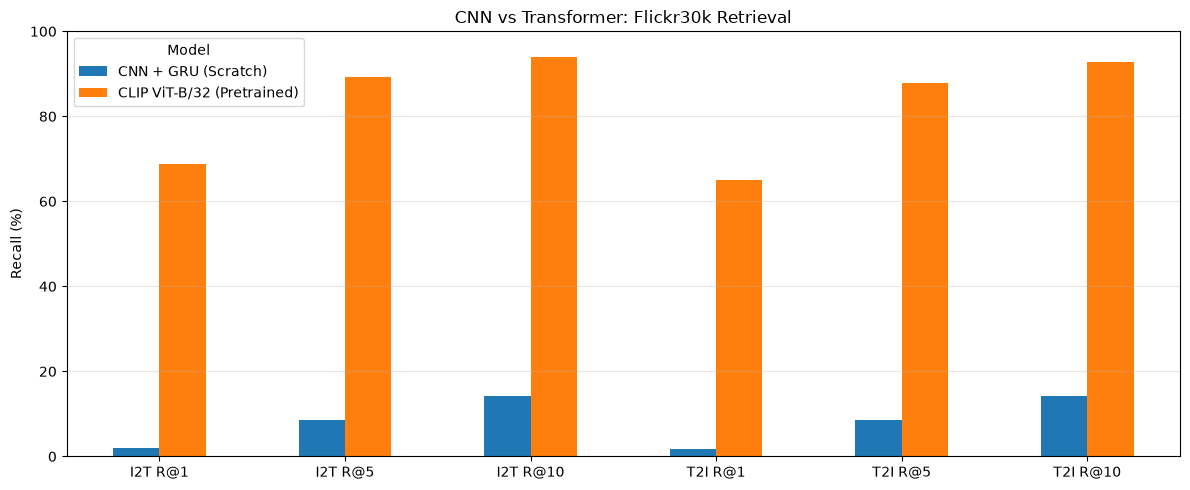

In [57]:

import pandas as pd
import matplotlib.pyplot as plt

# ========================================
# Cell 27: CNN vs Transformer Comparison
# ========================================

comparison_df = pd.DataFrame({
    "Model": [
        "CNN + GRU (Scratch)",
        "CLIP ViT-B/32 (Pretrained)"
    ],
    "I2T R@1": [
        cnn_i2t_results[1] * 100,
        clip_i2t_results[1] * 100
    ],
    "I2T R@5": [
        cnn_i2t_results[5] * 100,
        clip_i2t_results[5] * 100
    ],
    "I2T R@10": [
        cnn_i2t_results[10] * 100,
        clip_i2t_results[10] * 100
    ],
    "T2I R@1": [
        cnn_t2i_results[1] * 100,
        clip_t2i_results[1] * 100
    ],
    "T2I R@5": [
        cnn_t2i_results[5] * 100,
        clip_t2i_results[5] * 100
    ],
    "T2I R@10": [
        cnn_t2i_results[10] * 100,
        clip_t2i_results[10] * 100
    ]
})

print("CNN vs Transformer Retrieval Results:")
display(comparison_df.round(2))

# ========================================
# Plot Recall@K
# ========================================

metrics = [
    "I2T R@1", "I2T R@5", "I2T R@10",
    "T2I R@1", "T2I R@5", "T2I R@10"
]

ax = comparison_df.set_index("Model")[
    metrics
].T.plot(
    kind="bar",
    figsize=(12, 5),
    rot=0
)

ax.set_title("CNN vs Transformer: Flickr30k Retrieval")
ax.set_ylabel("Recall (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Quiz 1：Image–Text Matching 實驗結果與討論

### 1. 實驗方法

本次實驗使用 Flickr30k 資料集，比較 CNN 與 Transformer 兩種架構在影像與文字檢索任務上的表現。

**Model 1：CNN + GRU**

- 使用 CNN 作為影像編碼器（Image Encoder）。
- 使用 GRU 作為文字編碼器（Text Encoder）。
- 模型從零開始訓練，不使用預訓練權重。
- 使用 Contrastive Learning，使正確配對的圖片與文字特徵更加接近。
- 使用 29,000 張訓練圖片進行訓練。

**Model 2：CLIP ViT-B/32**

- 使用 Vision Transformer（ViT）作為影像編碼器。
- 使用 Transformer 作為文字編碼器。
- 使用預訓練模型，不額外進行 Fine-tuning。
- 透過 Cosine Similarity 計算影像與文字特徵的相似程度。

兩種模型皆使用 Flickr30k Validation Dataset 中的 1,014 張圖片進行評估，每張圖片固定選取一個 Caption。

### 2. 實驗結果

| 評估指標 | CNN + GRU | CLIP ViT-B/32 |
|---|---:|---:|
| Image-to-Text Recall@1 | 1.87% | **68.74%** |
| Image-to-Text Recall@5 | 8.58% | **89.25%** |
| Image-to-Text Recall@10 | 14.10% | **93.89%** |
| Text-to-Image Recall@1 | 1.78% | **65.09%** |
| Text-to-Image Recall@5 | 8.68% | **87.77%** |
| Text-to-Image Recall@10 | 14.30% | **92.90%** |

### 3. 結果分析

從實驗結果可以觀察到，預訓練 CLIP ViT-B/32 在所有評估指標上皆明顯優於從零訓練的 CNN + GRU。

在 Image-to-Text Retrieval 任務中，CNN + GRU 的 Recall@1 為 1.87%，而 CLIP 達到 68.74%，提升了 66.87 個百分點。

在 Text-to-Image Retrieval 任務中，CNN + GRU 的 Recall@1 為 1.78%，而 CLIP 達到 65.09%，同樣具有顯著差異。

造成差異的可能原因包括：

1. CNN + GRU 從零開始訓練，僅使用 Flickr30k 資料集，能學習到的影像與文字關聯較有限。
2. CLIP 已透過大規模影像與文字配對資料進行預訓練，因此具有較好的跨模態特徵表示能力。
3. CLIP 使用 Transformer 架構，能透過 Attention Mechanism 建立特徵之間的關聯。

需要注意的是，兩種模型除了架構不同，也存在預訓練方式與模型參數量的差異，因此不能將效能差距完全歸因於 CNN 與 Transformer 的架構差異。

### 4. 實驗結論

本次實驗比較了 CNN + GRU 與 CLIP ViT-B/32 在影像文字檢索任務上的表現。

實驗結果顯示，使用預訓練權重的 CLIP 在 Image-to-Text 與 Text-to-Image Retrieval 任務中皆具有明顯優勢。

這說明大規模影像文字預訓練對於跨模態特徵學習具有重要幫助，也展示了 CLIP 在影像與文字檢索任務中的實用性。

本次評估採用 Validation Dataset，並以每張圖片對應一個 Caption 的簡化方式計算 Recall@K，因此結果不直接等同於 Flickr30k 標準的五個 Caption 檢索評估。

# Quiz 2：多模態深度學習神經網路（Multimodal Deep Learning）

## 實驗目標

本實驗使用 Flickr30k 影像與文字資料集，建立多模態分類模型，判斷輸入圖片與文字描述是否正確配對。

透過不同的 Image Backbone 與 Text Backbone 萃取特徵，將兩種特徵進行融合（Feature Fusion），再使用 MLP 分類器完成二元分類。

## 模型架構

| 模型 | Image Backbone | Text Backbone | Feature Fusion |
|---|---|---|---|
| Model A | ResNet18 | DistilBERT | Concatenation + MLP |
| Model B | CLIP ViT-B/32 | CLIP Text Transformer | Concatenation + MLP |

## 評估方式

- **Accuracy**：分類準確率
- **Precision**：精確率
- **Recall**：召回率
- **F1-score**：綜合評估分類表現

## 實驗流程

1. 準備 Flickr30k 影像與文字配對資料。
2. 建立正確配對（Label 1）與錯誤配對（Label 0）。
3. 使用不同 Backbone 萃取影像與文字特徵。
4. 融合特徵並訓練分類器。
5. 進行分類推論，比較兩種模型的表現。

In [58]:

# ========================================
# Cell 28: CLIP Multimodal Classifier
# ========================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. 凍結 CLIP Backbone
clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False

# 2. 建立多模態分類模型
class CLIPMultimodalClassifier(nn.Module):

    def __init__(self, clip_backbone):
        super().__init__()

        self.clip = clip_backbone

        # Image: 512 + Text: 512 = 1024
        self.classifier = nn.Sequential(
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, pixel_values,
                input_ids, attention_mask):

        # 使用預訓練 CLIP 萃取特徵
        with torch.no_grad():

            image_features = self.clip.get_image_features(
                pixel_values=pixel_values
            )

            text_features = self.clip.get_text_features(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            image_features = F.normalize(
                image_features, dim=-1
            )

            text_features = F.normalize(
                text_features, dim=-1
            )

        # 特徵融合
        fused_features = torch.cat(
            [image_features, text_features],
            dim=1
        )

        # 分類
        logits = self.classifier(fused_features)

        return logits


# 3. 初始化模型
quiz2_clip_classifier = CLIPMultimodalClassifier(
    clip_model
).to(device)

# 4. 檢查參數
total_params = sum(
    p.numel()
    for p in quiz2_clip_classifier.parameters()
)

trainable_params = sum(
    p.numel()
    for p in quiz2_clip_classifier.parameters()
    if p.requires_grad
)

print("Model: CLIP ViT + Text Transformer + MLP")
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print("Device:", device)

# 5. 測試分類器輸出
dummy_image_features = torch.randn(2, 512).to(device)
dummy_text_features = torch.randn(2, 512).to(device)

dummy_fused = torch.cat(
    [dummy_image_features, dummy_text_features],
    dim=1
)

with torch.no_grad():
    dummy_logits = (
        quiz2_clip_classifier.classifier(dummy_fused)
    )

print("Fusion Shape:", dummy_fused.shape)
print("Output Shape:", dummy_logits.shape)

print("\nQuiz 2 CLIP Classifier Created!")


Model: CLIP ViT + Text Transformer + MLP
Total Parameters: 151,556,291
Trainable Parameters: 278,978
Device: cuda
Fusion Shape: torch.Size([2, 1024])
Output Shape: torch.Size([2, 2])

Quiz 2 CLIP Classifier Created!


In [59]:

# ========================================
# Cell 29: Multimodal Classification Dataset
# ========================================

import random
import io
import zipfile
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class FlickrMatchingDataset(Dataset):

    def __init__(self, dataframe, zip_path):
        self.df = dataframe.reset_index(drop=True)
        self.zip_path = zip_path
        self._zip_file = None

        # 固定每張圖片的第一個 Caption
        self.captions = [
            captions[0]
            for captions in self.df["captions"]
        ]

    def __len__(self):
        # 每張圖片產生一筆正樣本與一筆負樣本
        return len(self.df) * 2

    def __getitem__(self, idx):

        image_idx = idx // 2
        label = idx % 2

        row = self.df.iloc[image_idx]

        # 開啟 ZIP（避免每筆資料重複開啟）
        if self._zip_file is None:
            self._zip_file = zipfile.ZipFile(
                self.zip_path, "r"
            )

        image_path = (
            "flickr30k-images/" + row["filename"]
        )

        image_bytes = self._zip_file.read(
            image_path
        )

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        if label == 1:
            # 正確配對
            caption = self.captions[image_idx]

        else:
            # 錯誤配對：使用其他圖片的 Caption
            wrong_idx = random.randrange(len(self.df))

            while wrong_idx == image_idx:
                wrong_idx = random.randrange(len(self.df))

            caption = self.captions[wrong_idx]

        return {
            "image": image,
            "caption": caption,
            "label": label
        }


# ========================================
# 建立 Train / Validation Dataset
# ========================================

quiz2_train_dataset = FlickrMatchingDataset(
    train_df,
    ZIP_PATH
)

quiz2_val_dataset = FlickrMatchingDataset(
    val_df,
    ZIP_PATH
)

print("Train Samples:", len(quiz2_train_dataset))
print("Validation Samples:", len(quiz2_val_dataset))

# ========================================
# 檢查樣本
# ========================================

positive_sample = quiz2_train_dataset[1]
negative_sample = quiz2_train_dataset[0]

print("\nPositive Sample:")
print("Label:", positive_sample["label"])
print("Caption:", positive_sample["caption"])

print("\nNegative Sample:")
print("Label:", negative_sample["label"])
print("Caption:", negative_sample["caption"])

print("\nDataset Created Successfully!")


Train Samples: 58000
Validation Samples: 2028

Positive Sample:
Label: 1
Caption: Two young guys with shaggy hair look at their hands while hanging out in the yard.

Negative Sample:
Label: 0
Caption: A man working on a construction project on saw horses.

Dataset Created Successfully!


In [60]:

# ========================================
# Cell 30: CLIP DataLoader
# ========================================

import random
import torch
from torch.utils.data import DataLoader

# 1. 固定 Validation 的負樣本
class FixedFlickrMatchingDataset(FlickrMatchingDataset):

    def __init__(self, dataframe, zip_path, seed=42):
        super().__init__(dataframe, zip_path)

        rng = random.Random(seed)

        self.negative_indices = []

        for image_idx in range(len(self.df)):

            wrong_idx = rng.randrange(len(self.df))

            while wrong_idx == image_idx:
                wrong_idx = rng.randrange(len(self.df))

            self.negative_indices.append(wrong_idx)

    def __getitem__(self, idx):

        image_idx = idx // 2
        label = idx % 2

        row = self.df.iloc[image_idx]

        if self._zip_file is None:
            self._zip_file = zipfile.ZipFile(
                self.zip_path, "r"
            )

        image_path = (
            "flickr30k-images/" + row["filename"]
        )

        image_bytes = self._zip_file.read(image_path)

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        if label == 1:
            caption = self.captions[image_idx]
        else:
            caption = self.captions[
                self.negative_indices[image_idx]
            ]

        return {
            "image": image,
            "caption": caption,
            "label": label
        }


# 2. 建立固定的 Validation Dataset
quiz2_val_dataset = FixedFlickrMatchingDataset(
    val_df,
    ZIP_PATH,
    seed=42
)

# 3. CLIP 專用 Collate Function
def clip_matching_collate_fn(batch):

    images = [
        sample["image"]
        for sample in batch
    ]

    captions = [
        sample["caption"]
        for sample in batch
    ]

    labels = torch.tensor(
        [sample["label"] for sample in batch],
        dtype=torch.long
    )

    inputs = clip_processor(
        text=captions,
        images=images,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=77
    )

    inputs["labels"] = labels

    return inputs


# 4. 建立 DataLoader
QUIZ2_BATCH_SIZE = 16

quiz2_train_loader = DataLoader(
    quiz2_train_dataset,
    batch_size=QUIZ2_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=clip_matching_collate_fn,
    pin_memory=(device.type == "cuda")
)

quiz2_val_loader = DataLoader(
    quiz2_val_dataset,
    batch_size=QUIZ2_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=clip_matching_collate_fn,
    pin_memory=(device.type == "cuda")
)

# 5. 檢查第一個 Batch
batch = next(iter(quiz2_train_loader))

print("Pixel Values:", batch["pixel_values"].shape)
print("Input IDs:", batch["input_ids"].shape)
print("Attention Mask:", batch["attention_mask"].shape)
print("Labels:", batch["labels"].shape)

print("\nLabels:", batch["labels"].tolist())

print("\nCLIP DataLoader Created Successfully!")


Pixel Values: torch.Size([16, 3, 224, 224])
Input IDs: torch.Size([16, 35])
Attention Mask: torch.Size([16, 35])
Labels: torch.Size([16])

Labels: [1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1]

CLIP DataLoader Created Successfully!


In [61]:

# ========================================
# Cell 31: Train CLIP Multimodal Classifier
# ========================================

import torch
import torch.nn as nn
from tqdm.auto import tqdm

QUIZ2_EPOCHS = 5
QUIZ2_LR = 1e-3

quiz2_optimizer = torch.optim.AdamW(
    quiz2_clip_classifier.classifier.parameters(),
    lr=QUIZ2_LR,
    weight_decay=1e-4
)

quiz2_criterion = nn.CrossEntropyLoss()

QUIZ2_SAVE_PATH = (
    WEEK5_DIR / "quiz2_clip_classifier_best.pth"
)

quiz2_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

# ========================================
# Training Loop
# ========================================

for epoch in range(QUIZ2_EPOCHS):

    quiz2_clip_classifier.train()

    # 凍結的 CLIP 保持 eval 模式
    quiz2_clip_classifier.clip.eval()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        quiz2_train_loader,
        desc=f"Epoch {epoch+1}/{QUIZ2_EPOCHS}"
    )

    for batch in train_bar:

        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        quiz2_optimizer.zero_grad()

        logits = quiz2_clip_classifier(
            pixel_values,
            input_ids,
            attention_mask
        )

        loss = quiz2_criterion(logits, labels)

        loss.backward()
        quiz2_optimizer.step()

        predictions = logits.argmax(dim=1)

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            predictions == labels
        ).sum().item()
        train_total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ====================================
    # Validation
    # ====================================

    quiz2_clip_classifier.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for batch in quiz2_val_loader:

            pixel_values = batch["pixel_values"].to(device)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = quiz2_clip_classifier(
                pixel_values,
                input_ids,
                attention_mask
            )

            loss = quiz2_criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            val_loss += loss.item() * labels.size(0)
            val_correct += (
                predictions == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # ====================================
    # Record Results
    # ====================================

    quiz2_history["train_loss"].append(train_loss)
    quiz2_history["train_acc"].append(train_acc)
    quiz2_history["val_loss"].append(val_loss)
    quiz2_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{QUIZ2_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    # ====================================
    # Save Best Model
    # ====================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            quiz2_clip_classifier.classifier.state_dict(),
            QUIZ2_SAVE_PATH
        )

        print(
            f"Best Model Saved! "
            f"Val Acc: {best_val_acc*100:.2f}%"
        )

print("\nTraining Finished!")
print(f"Best Validation Accuracy: {best_val_acc*100:.2f}%")
print("Saved Model:", QUIZ2_SAVE_PATH)


Epoch 1/5:   0%|          | 0/3625 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 0.3389 | Train Acc: 83.99% | Val Loss: 0.2102 | Val Acc: 92.41%
Best Model Saved! Val Acc: 92.41%


Epoch 2/5:   0%|          | 0/3625 [00:00<?, ?it/s]

Epoch 2/5 | Train Loss: 0.2124 | Train Acc: 91.66% | Val Loss: 0.1680 | Val Acc: 93.84%
Best Model Saved! Val Acc: 93.84%


Epoch 3/5:   0%|          | 0/3625 [00:00<?, ?it/s]

Epoch 3/5 | Train Loss: 0.1889 | Train Acc: 92.63% | Val Loss: 0.1540 | Val Acc: 93.84%


Epoch 4/5:   0%|          | 0/3625 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 0.1676 | Train Acc: 93.71% | Val Loss: 0.1491 | Val Acc: 94.28%
Best Model Saved! Val Acc: 94.28%


Epoch 5/5:   0%|          | 0/3625 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1542 | Train Acc: 94.15% | Val Loss: 0.1477 | Val Acc: 94.28%

Training Finished!
Best Validation Accuracy: 94.28%
Saved Model: D:\project\MMIP\week5\quiz2_clip_classifier_best.pth


Validation Accuracy: 94.28%

Classification Report:

              precision    recall  f1-score   support

   Not Match     0.9545    0.9300    0.9421      1014
       Match     0.9317    0.9556    0.9435      1014

    accuracy                         0.9428      2028
   macro avg     0.9431    0.9428    0.9428      2028
weighted avg     0.9431    0.9428    0.9428      2028



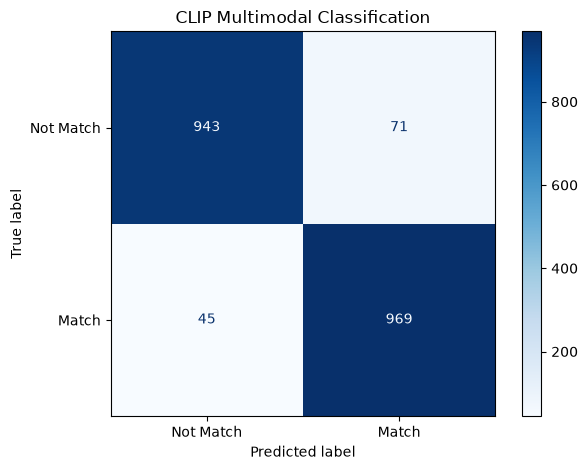


Quiz 2 Evaluation Finished!


In [62]:

# ========================================
# Cell 32: CLIP Classification Evaluation
# ========================================

import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. 載入最佳分類器
quiz2_clip_classifier.classifier.load_state_dict(
    torch.load(
        QUIZ2_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

quiz2_clip_classifier.eval()

all_labels = []
all_predictions = []

# 2. Validation 推論
with torch.inference_mode():

    for batch in quiz2_val_loader:

        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        logits = quiz2_clip_classifier(
            pixel_values,
            input_ids,
            attention_mask
        )

        predictions = logits.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            batch["labels"].tolist()
        )

# 3. 計算 Accuracy
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Validation Accuracy: {accuracy*100:.2f}%")

# 4. Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Not Match", "Match"],
        digits=4
    )
)

# 5. Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Match", "Match"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("CLIP Multimodal Classification")
plt.tight_layout()
plt.show()

print("\nQuiz 2 Evaluation Finished!")


Quiz 2: Multimodal Classification Comparison


,Model,Image Backbone,Text Backbone,Validation Accuracy (%)
0,ResNet18 + DistilBERT,ResNet18 (CNN),DistilBERT,51.40
1,CLIP ViT-B/32 + CLIP Text,CLIP ViT-B/32 (Transformer),CLIP Text Transformer,94.28


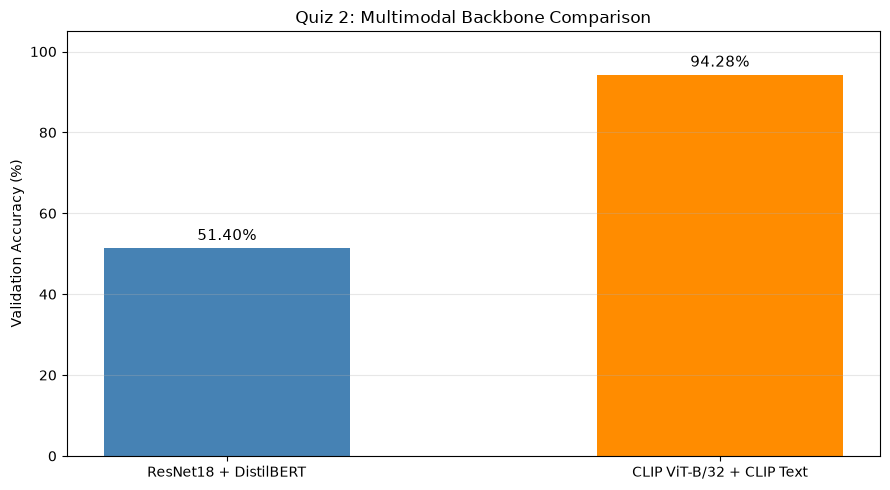

CLIP Accuracy Improvement: 42.88 percentage points

Quiz 2 Comparison Finished!


In [63]:

# ========================================
# Cell 33: Quiz 2 Model Comparison
# ========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. 整理模型比較結果
quiz2_comparison = pd.DataFrame({
    "Model": [
        "ResNet18 + DistilBERT",
        "CLIP ViT-B/32 + CLIP Text"
    ],
    "Image Backbone": [
        "ResNet18 (CNN)",
        "CLIP ViT-B/32 (Transformer)"
    ],
    "Text Backbone": [
        "DistilBERT",
        "CLIP Text Transformer"
    ],
    "Validation Accuracy (%)": [
        51.40,
        94.28
    ]
})

print("Quiz 2: Multimodal Classification Comparison")
display(quiz2_comparison)

# 2. 繪製比較圖
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    quiz2_comparison["Model"],
    quiz2_comparison["Validation Accuracy (%)"],
    color=["steelblue", "darkorange"],
    width=0.5
)

ax.set_title(
    "Quiz 2: Multimodal Backbone Comparison"
)
ax.set_ylabel("Validation Accuracy (%)")
ax.set_ylim(0, 105)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.2f}%",
        ha="center",
        fontsize=11
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 3. 計算差異
improvement = 94.28 - 51.40

print(
    f"CLIP Accuracy Improvement: "
    f"{improvement:.2f} percentage points"
)

print("\nQuiz 2 Comparison Finished!")


## Quiz 2：實驗結果與討論

### 實驗結果

本實驗使用 Flickr30k 資料集，建立影像與文字的多模態二元分類模型，判斷圖片與文字描述是否正確配對。

實驗比較兩種 Backbone 組合：

1. **ResNet18 + DistilBERT**：使用 CNN 萃取影像特徵，DistilBERT 萃取文字特徵，融合後透過 MLP 進行分類。
2. **CLIP ViT-B/32 + CLIP Text Transformer**：使用預訓練 CLIP 萃取影像與文字特徵，透過 Concatenation 融合後，訓練 MLP 分類器。

兩種模型的 Validation Accuracy 分別為 51.40% 與 94.28%，CLIP 模型高出 42.88 個百分點。

### 結果分析

CLIP 模型在多模態分類任務中具有明顯較好的表現。其主要原因可能是 CLIP 已透過大規模影像文字配對資料進行預訓練，能夠將語意相近的圖片與文字映射到相近的特徵空間。

CLIP 分類模型的 Validation Accuracy 為 94.28%，其中 Match 類別的 F1-score 為 94.35%，Not Match 類別的 F1-score 為 94.21%，顯示模型對兩種類別都有良好的辨識能力。

然而，兩個模型使用的預訓練方式與驗證負樣本設定可能不同，因此效能差異不能完全歸因於 Backbone 架構。

### 實驗結論

本次實驗成功使用不同的影像與文字 Backbone 建立多模態分類模型，並完成模型訓練、推論及結果比較。

實驗顯示，使用預訓練 CLIP 的模型在目前的影像文字配對分類任務中表現較佳，證明預訓練跨模態特徵對分類任務具有明顯幫助。

In [64]:

# ========================================
# Cell 34: Save Quiz 2 Results
# ========================================

import torch
import json
import pandas as pd
from pathlib import Path

SAVE_DIR = WEEK5_DIR / "quiz2_saved"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. 儲存最佳 CLIP 分類器
quiz2_clip_classifier.classifier.load_state_dict(
    torch.load(
        QUIZ2_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

torch.save(
    quiz2_clip_classifier.classifier.state_dict(),
    SAVE_DIR / "clip_classifier_best.pth"
)

# 2. 儲存訓練歷史
with open(
    SAVE_DIR / "training_history.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(quiz2_history, f, indent=4)

# 3. 儲存模型設定
model_config = {
    "pretrained_model": "openai/clip-vit-base-patch32",
    "image_backbone": "CLIP ViT-B/32",
    "text_backbone": "CLIP Text Transformer",
    "feature_fusion": "Concatenation",
    "classifier_input_dim": 1024,
    "classifier_hidden_dims": [256, 64],
    "num_classes": 2,
    "class_names": ["Not Match", "Match"],
    "best_validation_accuracy": 0.9428,
    "batch_size": 16,
    "epochs": 5,
    "learning_rate": 0.001
}

with open(
    SAVE_DIR / "model_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_config, f, indent=4)

# 4. 儲存模型比較結果
quiz2_comparison.to_csv(
    SAVE_DIR / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. 確認檔案
print("Quiz 2 Saved Files:\n")

for file in SAVE_DIR.iterdir():
    print(
        file.name,
        f"({file.stat().st_size / 1024:.1f} KB)"
    )

print("\nAll Quiz 2 Results Saved Successfully!")


Quiz 2 Saved Files:

clip_classifier_best.pth (1092.5 KB)
model_comparison.csv (0.2 KB)
model_config.json (0.5 KB)
training_history.json (0.7 KB)

All Quiz 2 Results Saved Successfully!


# Quiz 3：CLIP Image Captioning

本實驗使用預訓練 CLIP 作為 Image Encoder，搭配文字 Decoder 建立 Image Captioning 模型，根據輸入影像自動產生英文描述。

完成模型訓練與影像描述生成後，將與 Week 4 的 Image Captioning 模型比較 BLEU 和 BERTScore。

In [1]:
# ========================================
# Quiz 3 - Cell 1: Environment Check
# ========================================

from pathlib import Path
import torch
import pandas as pd
import os

WEEK5_DIR = Path(r"D:\project\MMIP\week5")
FLICKR_DIR = WEEK5_DIR / "data" / "Flickr30k"

ZIP_PATH = FLICKR_DIR / "flickr30k-images.zip"
CSV_PATH = FLICKR_DIR / "flickr_annotations_30k.csv"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Current Directory:", os.getcwd())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset Check:")
print("Flickr30k ZIP:", ZIP_PATH.exists())
print("Annotations CSV:", CSV_PATH.exists())

print("\nSaved Model Check:")

model_files = [
    "quiz2_multimodal_best.pth",
    "quiz2_clip_classifier_best.pth",
    "quiz2_saved/clip_classifier_best.pth",
]

for filename in model_files:
    path = WEEK5_DIR / filename
    print(f"{filename}: {'Found' if path.exists() else 'Not Found'}")

print("\nEnvironment Check Finished!")

Current Directory: D:\project\MMIP\week5
Device: cuda
GPU: NVIDIA GeForce RTX 2060

Dataset Check:
Flickr30k ZIP: True
Annotations CSV: True

Saved Model Check:
quiz2_multimodal_best.pth: Found
quiz2_clip_classifier_best.pth: Found
quiz2_saved/clip_classifier_best.pth: Found

Environment Check Finished!


In [3]:
# ========================================
# Quiz 3 - Check Original CSV Columns
# ========================================

import pandas as pd

caption_df = pd.read_csv(CSV_PATH)

print("CSV Columns:")
print(caption_df.columns.tolist())

print("\nFirst 3 Rows:")
display(caption_df.head(3))

CSV Columns:
['raw', 'sentids', 'split', 'filename', 'img_id']

First 3 Rows:


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2


In [4]:

# ========================================
# Quiz 3 - Cell 2: Prepare Caption Dataset
# ========================================

import pandas as pd
import ast
import zipfile

# 1. 讀取 Flickr30k CSV
caption_df = pd.read_csv(CSV_PATH)

# 2. 將 raw 欄位轉換成 Caption List
caption_df["captions"] = caption_df["raw"].apply(
    ast.literal_eval
)

# 3. 分割 Train / Validation / Test
caption_train_df = caption_df[
    caption_df["split"] == "train"
].reset_index(drop=True)

caption_val_df = caption_df[
    caption_df["split"] == "val"
].reset_index(drop=True)

caption_test_df = caption_df[
    caption_df["split"] == "test"
].reset_index(drop=True)

# 4. 顯示資料數量
print("Train Images:", len(caption_train_df))
print("Validation Images:", len(caption_val_df))
print("Test Images:", len(caption_test_df))

# 5. 顯示一張圖片的五句 Caption
print("\nSample Filename:")
print(caption_train_df.iloc[0]["filename"])

print("\nSample Captions:")

for i, caption in enumerate(
    caption_train_df.iloc[0]["captions"], 1
):
    print(f"{i}. {caption}")

# 6. 確認圖片存在 ZIP 中
with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    image_path = (
        "flickr30k-images/" +
        caption_train_df.iloc[0]["filename"]
    )

    print(
        "\nImage Exists in ZIP:",
        image_path in zf.namelist()
    )

print("\nQuiz 3 Dataset Ready!")


Train Images: 29000
Validation Images: 1014
Test Images: 1000

Sample Filename:
1000092795.jpg

Sample Captions:
1. Two young guys with shaggy hair look at their hands while hanging out in the yard.
2. Two young, White males are outside near many bushes.
3. Two men in green shirts are standing in a yard.
4. A man in a blue shirt standing in a garden.
5. Two friends enjoy time spent together.

Image Exists in ZIP: True

Quiz 3 Dataset Ready!


In [5]:

# ========================================
# Quiz 3 - Cell 3: Prepare Tokenizer
# ========================================

from transformers import AutoTokenizer
import torch

# 1. 載入 GPT-2 Tokenizer
CAPTION_TOKENIZER_NAME = "gpt2"

caption_tokenizer = AutoTokenizer.from_pretrained(
    CAPTION_TOKENIZER_NAME
)

# 2. 設定特殊 Token
# GPT-2 原本沒有 pad_token
caption_tokenizer.pad_token = caption_tokenizer.eos_token

BOS_ID = caption_tokenizer.bos_token_id
EOS_ID = caption_tokenizer.eos_token_id
PAD_ID = caption_tokenizer.pad_token_id

MAX_CAPTION_LENGTH = 40

# 3. 測試一段 Caption
sample_caption = caption_train_df.iloc[0]["captions"][0]

encoded = caption_tokenizer(
    sample_caption,
    add_special_tokens=False,
    truncation=True,
    max_length=MAX_CAPTION_LENGTH - 2
)

# 手動加入開始與結束 Token
token_ids = [BOS_ID] + encoded["input_ids"] + [EOS_ID]

print("Tokenizer:", CAPTION_TOKENIZER_NAME)
print("Vocabulary Size:", len(caption_tokenizer))
print("BOS Token ID:", BOS_ID)
print("EOS Token ID:", EOS_ID)
print("PAD Token ID:", PAD_ID)

print("\nOriginal Caption:")
print(sample_caption)

print("\nToken IDs:")
print(token_ids)

print("\nDecoded Caption:")
print(
    caption_tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    )
)

print("\nToken Count:", len(token_ids))
print("Max Caption Length:", MAX_CAPTION_LENGTH)
print("\nTokenizer Ready!")


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer: gpt2
Vocabulary Size: 50257
BOS Token ID: 50256
EOS Token ID: 50256
PAD Token ID: 50256

Original Caption:
Two young guys with shaggy hair look at their hands while hanging out in the yard.

Token IDs:
[50256, 7571, 1862, 3730, 351, 427, 363, 1360, 4190, 804, 379, 511, 2832, 981, 10938, 503, 287, 262, 12699, 13, 50256]

Decoded Caption:
Two young guys with shaggy hair look at their hands while hanging out in the yard.

Token Count: 21
Max Caption Length: 40

Tokenizer Ready!


CLIP Model: openai/clip-vit-base-patch32
Image Filename: 1000092795.jpg
Image Size: (333, 500)

Pixel Values Shape: (1, 3, 224, 224)
Image Features Shape: (1, 512)

Feature Dimension: 512
CLIP Trainable Parameters: 0

CLIP Image Encoder Ready!


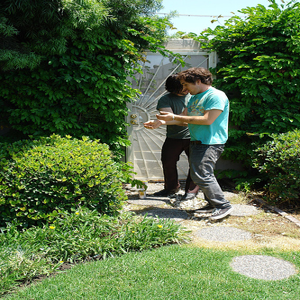

In [6]:

# ========================================
# Quiz 3 - Cell 4: Load CLIP Image Encoder
# ========================================

from transformers import CLIPModel, CLIPProcessor
from PIL import Image
from io import BytesIO
import zipfile
import torch

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

# 1. 載入預訓練 CLIP
clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL_NAME
)

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_NAME
).to(device)

# 2. 凍結 CLIP 所有參數
for param in clip_model.parameters():
    param.requires_grad = False

clip_model.eval()

# 3. 讀取一張 Flickr30k 圖片
sample_filename = caption_train_df.iloc[0]["filename"]

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    image_bytes = zf.read(
        "flickr30k-images/" + sample_filename
    )

sample_image = Image.open(
    BytesIO(image_bytes)
).convert("RGB")

# 4. 圖片前處理
image_inputs = clip_processor(
    images=sample_image,
    return_tensors="pt"
)

pixel_values = image_inputs["pixel_values"].to(device)

# 5. 萃取影像特徵
with torch.no_grad():
    image_features = clip_model.get_image_features(
        pixel_values=pixel_values
    )

# 6. 顯示結果
print("CLIP Model:", CLIP_MODEL_NAME)
print("Image Filename:", sample_filename)
print("Image Size:", sample_image.size)

print("\nPixel Values Shape:", tuple(pixel_values.shape))
print("Image Features Shape:", tuple(image_features.shape))

print("\nFeature Dimension:", image_features.shape[-1])

trainable_params = sum(
    p.numel() for p in clip_model.parameters()
    if p.requires_grad
)

print("CLIP Trainable Parameters:", trainable_params)

print("\nCLIP Image Encoder Ready!")

display(sample_image.resize((300, 300)))


In [7]:

# ========================================
# Quiz 3 - Cell 5: Build Transformer Decoder
# ========================================

import torch
import torch.nn as nn

class CLIPCaptioningModel(nn.Module):
    def __init__(
        self,
        clip_encoder,
        vocab_size=50257,
        d_model=256,
        nhead=4,
        num_layers=2,
        max_length=40
    ):
        super().__init__()

        # 1. 預訓練 CLIP Image Encoder
        self.clip_encoder = clip_encoder

        for param in self.clip_encoder.parameters():
            param.requires_grad = False

        # 2. CLIP Patch Features: 768 → 256
        self.image_projection = nn.Linear(768, d_model)

        # 3. 文字 Token Embedding
        self.token_embedding = nn.Embedding(
            vocab_size, d_model
        )

        # 4. 位置 Embedding
        self.position_embedding = nn.Embedding(
            max_length, d_model
        )

        # 5. Transformer Decoder
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=1024,
            dropout=0.1,
            batch_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers
        )

        # 6. 輸出每個 Token 的預測
        self.output_layer = nn.Linear(
            d_model, vocab_size
        )

    def forward(self, pixel_values, input_ids):

        # CLIP Encoder 不進行梯度更新
        with torch.no_grad():
            vision_outputs = self.clip_encoder.vision_model(
                pixel_values=pixel_values
            )

            image_tokens = vision_outputs.last_hidden_state

        # Image Tokens: [B, 50, 768] → [B, 50, 256]
        memory = self.image_projection(image_tokens)

        batch_size, seq_len = input_ids.shape

        positions = torch.arange(
            seq_len,
            device=input_ids.device
        ).unsqueeze(0)

        # Text Embedding + Position Embedding
        text_features = (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )

        # Causal Mask：禁止看到未來 Token
        causal_mask = nn.Transformer.generate_square_subsequent_mask(
            seq_len,
            device=input_ids.device
        )

        # Transformer Decoder
        decoded = self.decoder(
            tgt=text_features,
            memory=memory,
            tgt_mask=causal_mask
        )

        # [B, seq_len, vocab_size]
        logits = self.output_layer(decoded)

        return logits


# ========================================
# 建立模型
# ========================================

caption_model = CLIPCaptioningModel(
    clip_encoder=clip_model,
    vocab_size=len(caption_tokenizer),
    max_length=MAX_CAPTION_LENGTH
).to(device)

# ========================================
# 測試 Forward Pass
# ========================================

caption_model.eval()

test_input_ids = torch.tensor(
    [token_ids],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    test_logits = caption_model(
        pixel_values=pixel_values,
        input_ids=test_input_ids
    )

print("Input Image:", tuple(pixel_values.shape))
print("Input Token IDs:", tuple(test_input_ids.shape))
print("Output Logits:", tuple(test_logits.shape))

total_params = sum(
    p.numel() for p in caption_model.parameters()
)

trainable_params = sum(
    p.numel() for p in caption_model.parameters()
    if p.requires_grad
)

print(f"\nTotal Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

print("\nTransformer Decoder Ready!")


Input Image: (1, 3, 224, 224)
Input Token IDs: (1, 21)
Output Logits: (1, 21, 50257)

Total Parameters: 179,373,138
Trainable Parameters: 28,095,825

Transformer Decoder Ready!


In [8]:

# ========================================
# Quiz 3 - Cell 6: Caption Dataset
# ========================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from io import BytesIO
import zipfile
import random
import torch

class FlickrCaptionDataset(Dataset):

    def __init__(self, dataframe, zip_path, tokenizer,
                 processor, max_length=40):

        self.df = dataframe.reset_index(drop=True)
        self.zip_path = zip_path
        self.tokenizer = tokenizer
        self.processor = processor
        self.max_length = max_length

        # 延遲開啟 ZIP，避免 DataLoader 問題
        self.zip_file = None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # 1. 讀取圖片
        if self.zip_file is None:
            self.zip_file = zipfile.ZipFile(
                self.zip_path, "r"
            )

        image_bytes = self.zip_file.read(
            "flickr30k-images/" + row["filename"]
        )

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # 2. CLIP 圖片前處理
        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        )["pixel_values"].squeeze(0)

        # 3. 從五句 Caption 中隨機選一句
        caption = random.choice(row["captions"])

        # 4. Tokenize
        encoded = self.tokenizer(
            caption,
            add_special_tokens=False,
            truncation=True,
            max_length=self.max_length - 2
        )

        ids = (
            [BOS_ID]
            + encoded["input_ids"]
            + [EOS_ID]
        )

        # 5. Teacher Forcing
        input_ids = ids[:-1]
        labels = ids[1:]

        # 6. Padding
        pad_length = (self.max_length - 1) - len(input_ids)

        input_ids += [PAD_ID] * pad_length
        labels += [-100] * pad_length

        return {
            "pixel_values": pixel_values,
            "input_ids": torch.tensor(
                input_ids, dtype=torch.long
            ),
            "labels": torch.tensor(
                labels, dtype=torch.long
            ),
            "caption": caption
        }


# ========================================
# 建立 Train / Validation Dataset
# ========================================

quiz3_train_dataset = FlickrCaptionDataset(
    caption_train_df,
    ZIP_PATH,
    caption_tokenizer,
    clip_processor,
    MAX_CAPTION_LENGTH
)

quiz3_val_dataset = FlickrCaptionDataset(
    caption_val_df,
    ZIP_PATH,
    caption_tokenizer,
    clip_processor,
    MAX_CAPTION_LENGTH
)

# RTX 2060 6GB：先使用 Batch Size 4
QUIZ3_BATCH_SIZE = 4

quiz3_train_loader = DataLoader(
    quiz3_train_dataset,
    batch_size=QUIZ3_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

quiz3_val_loader = DataLoader(
    quiz3_val_dataset,
    batch_size=QUIZ3_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ========================================
# 測試一個 Batch
# ========================================

sample_batch = next(iter(quiz3_train_loader))

print("Train Images:", len(quiz3_train_dataset))
print("Validation Images:", len(quiz3_val_dataset))

print("\nBatch Shapes:")
print(
    "Pixel Values:",
    tuple(sample_batch["pixel_values"].shape)
)
print(
    "Input IDs:",
    tuple(sample_batch["input_ids"].shape)
)
print(
    "Labels:",
    tuple(sample_batch["labels"].shape)
)

print("\nSample Caption:")
print(sample_batch["caption"][0])

print("\nValid Target Tokens:",
      (sample_batch["labels"][0] != -100).sum().item())

print("\nQuiz 3 DataLoader Ready!")


Train Images: 29000
Validation Images: 1014

Batch Shapes:
Pixel Values: (4, 3, 224, 224)
Input IDs: (4, 39)
Labels: (4, 39)

Sample Caption:
A man holding a violin is slacklining

Valid Target Tokens: 9

Quiz 3 DataLoader Ready!


In [9]:

# ========================================
# Quiz 3 - Cell 7: Add Padding Mask
# ========================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# 更新模型的 forward 方法
def caption_forward(self, pixel_values, input_ids, labels=None):

    # 1. CLIP Image Encoder（凍結）
    with torch.no_grad():
        vision_outputs = self.clip_encoder.vision_model(
            pixel_values=pixel_values
        )
        image_tokens = vision_outputs.last_hidden_state

    # 2. Image Features: 768 → 256
    memory = self.image_projection(image_tokens)

    batch_size, seq_len = input_ids.shape

    # 3. Text Embedding
    positions = torch.arange(
        seq_len,
        device=input_ids.device
    ).unsqueeze(0)

    text_features = (
        self.token_embedding(input_ids)
        + self.position_embedding(positions)
    )

    # 4. Causal Mask：不能看到未來的 Token
    causal_mask = nn.Transformer.generate_square_subsequent_mask(
        seq_len,
        device=input_ids.device
    )

    # 5. Padding Mask
    # labels = -100 代表 Padding 位置
    if labels is not None:
        padding_mask = (labels == -100)
    else:
        padding_mask = None

    # 6. Transformer Decoder
    decoded = self.decoder(
        tgt=text_features,
        memory=memory,
        tgt_mask=causal_mask,
        tgt_key_padding_mask=padding_mask
    )

    # 7. 預測 Token
    logits = self.output_layer(decoded)

    return logits


# 套用新的 forward 方法
CLIPCaptioningModel.forward = caption_forward

# ========================================
# 測試 Forward + Loss
# ========================================

caption_model.eval()

batch_images = sample_batch["pixel_values"].to(device)
batch_input_ids = sample_batch["input_ids"].to(device)
batch_labels = sample_batch["labels"].to(device)

with torch.no_grad():
    logits = caption_model(
        pixel_values=batch_images,
        input_ids=batch_input_ids,
        labels=batch_labels
    )

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        batch_labels.reshape(-1),
        ignore_index=-100
    )

print("Logits Shape:", tuple(logits.shape))
print("Labels Shape:", tuple(batch_labels.shape))
print("Initial Loss:", round(loss.item(), 4))

print("Loss Is Finite:", torch.isfinite(loss).item())
print("\nPadding Mask and Loss Ready!")


Logits Shape: (4, 39, 50257)
Labels Shape: (4, 39)
Initial Loss: 10.9974
Loss Is Finite: True

Padding Mask and Loss Ready!


C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


In [10]:

# ========================================
# Quiz 3 - Cell 8: Fix Mask + GPU Memory Test
# ========================================

import torch
import torch.nn.functional as F

def caption_forward_fixed(
    self, pixel_values, input_ids, labels=None
):
    # 1. CLIP Image Encoder
    with torch.no_grad():
        image_tokens = self.clip_encoder.vision_model(
            pixel_values=pixel_values
        ).last_hidden_state

    # 2. Image Projection
    memory = self.image_projection(image_tokens)

    # 3. Text Embedding
    batch_size, seq_len = input_ids.shape

    positions = torch.arange(
        seq_len, device=input_ids.device
    ).unsqueeze(0)

    text_features = (
        self.token_embedding(input_ids)
        + self.position_embedding(positions)
    )

    # 4. Boolean Causal Mask
    # True = 不允許 Attention
    causal_mask = torch.triu(
        torch.ones(
            seq_len, seq_len,
            device=input_ids.device,
            dtype=torch.bool
        ),
        diagonal=1
    )

    # 5. Boolean Padding Mask
    padding_mask = (
        labels == -100
        if labels is not None
        else None
    )

    # 6. Transformer Decoder
    decoded = self.decoder(
        tgt=text_features,
        memory=memory,
        tgt_mask=causal_mask,
        tgt_key_padding_mask=padding_mask
    )

    return self.output_layer(decoded)


# 更新 Forward
CLIPCaptioningModel.forward = caption_forward_fixed

# 確保 CLIP 維持 Eval 模式
caption_model.train()
caption_model.clip_encoder.eval()

# 清空梯度
caption_model.zero_grad(set_to_none=True)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# 混合精度測試
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=(device.type == "cuda")
):
    logits = caption_model(
        pixel_values=batch_images,
        input_ids=batch_input_ids,
        labels=batch_labels
    )

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        batch_labels.reshape(-1),
        ignore_index=-100
    )

# 反向傳播測試
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

scaler.scale(loss).backward()

print("Loss:", round(loss.item(), 4))
print("Loss Is Finite:", torch.isfinite(loss).item())

if torch.cuda.is_available():
    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**3
    )
    print(f"Peak GPU Memory: {peak_memory:.2f} GB")

# 測試完成，清除梯度
caption_model.zero_grad(set_to_none=True)
del logits, loss

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nForward and Backward Test Completed!")


Loss: 10.9845
Loss Is Finite: True
Peak GPU Memory: 0.81 GB

Forward and Backward Test Completed!


In [11]:

# ========================================
# Quiz 3 - Cell 9: Training Setup
# ========================================

import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm
import time

# 1. 訓練設定
QUIZ3_EPOCHS = 5
QUIZ3_LR = 1e-4

QUIZ3_SAVE_DIR = WEEK5_DIR / "quiz3_saved"
QUIZ3_SAVE_DIR.mkdir(parents=True, exist_ok=True)

QUIZ3_BEST_PATH = (
    QUIZ3_SAVE_DIR / "clip_caption_best.pth"
)

# 2. Optimizer：只更新可訓練參數
quiz3_optimizer = torch.optim.AdamW(
    [
        p for p in caption_model.parameters()
        if p.requires_grad
    ],
    lr=QUIZ3_LR,
    weight_decay=0.01
)

# 3. Mixed Precision
quiz3_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# 4. 訓練紀錄
quiz3_history = {
    "train_loss": [],
    "val_loss": []
}

quiz3_best_val_loss = float("inf")

# 5. 確認訓練參數
trainable_params = sum(
    p.numel()
    for p in caption_model.parameters()
    if p.requires_grad
)

print("Epochs:", QUIZ3_EPOCHS)
print("Batch Size:", QUIZ3_BATCH_SIZE)
print("Learning Rate:", QUIZ3_LR)
print("Trainable Parameters:", f"{trainable_params:,}")

print("\nTrain Batches:", len(quiz3_train_loader))
print("Validation Batches:", len(quiz3_val_loader))

print("\nBest Model Path:")
print(QUIZ3_BEST_PATH)

print("\nTraining Setup Ready!")


Epochs: 5
Batch Size: 4
Learning Rate: 0.0001
Trainable Parameters: 28,095,825

Train Batches: 7250
Validation Batches: 254

Best Model Path:
D:\project\MMIP\week5\quiz3_saved\clip_caption_best.pth

Training Setup Ready!


In [12]:

# ========================================
# Quiz 3 - Cell 10: Trial Training (100 Batches)
# ========================================

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
import time

TRIAL_BATCHES = 100

caption_model.train()

# CLIP 維持 Eval Mode
caption_model.clip_encoder.eval()

running_loss = 0.0
start_time = time.time()

progress_bar = tqdm(
    quiz3_train_loader,
    total=TRIAL_BATCHES,
    desc="Quiz 3 Trial Training"
)

for batch_idx, batch in enumerate(progress_bar):

    if batch_idx >= TRIAL_BATCHES:
        break

    images = batch["pixel_values"].to(device)
    input_ids = batch["input_ids"].to(device)
    labels = batch["labels"].to(device)

    quiz3_optimizer.zero_grad(set_to_none=True)

    # Mixed Precision
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):
        logits = caption_model(
            pixel_values=images,
            input_ids=input_ids,
            labels=labels
        )

        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1),
            ignore_index=-100
        )

    # Backward
    quiz3_scaler.scale(loss).backward()

    # Gradient Clipping
    quiz3_scaler.unscale_(quiz3_optimizer)

    torch.nn.utils.clip_grad_norm_(
        [
            p for p in caption_model.parameters()
            if p.requires_grad
        ],
        max_norm=1.0
    )

    quiz3_scaler.step(quiz3_optimizer)
    quiz3_scaler.update()

    running_loss += loss.item()

    progress_bar.set_postfix(
        loss=f"{loss.item():.4f}",
        avg_loss=f"{running_loss / (batch_idx + 1):.4f}"
    )

elapsed = time.time() - start_time

# ========================================
# 儲存試訓練 Checkpoint
# ========================================

trial_path = (
    QUIZ3_SAVE_DIR / "clip_caption_trial.pth"
)

# 不儲存 Frozen CLIP 權重
trainable_state = {
    k: v.cpu()
    for k, v in caption_model.state_dict().items()
    if not k.startswith("clip_encoder.")
}

torch.save(
    {
        "model_state_dict": trainable_state,
        "optimizer_state_dict": quiz3_optimizer.state_dict(),
        "scaler_state_dict": quiz3_scaler.state_dict(),
        "completed_batches": TRIAL_BATCHES,
        "average_loss": running_loss / TRIAL_BATCHES
    },
    trial_path
)

print("\nTrial Training Finished!")
print(f"Average Loss: {running_loss / TRIAL_BATCHES:.4f}")
print(f"Elapsed Time: {elapsed / 60:.2f} minutes")
print(f"Estimated Epoch Time: {elapsed / TRIAL_BATCHES * 7250 / 60:.1f} minutes")
print("Checkpoint Saved:", trial_path)


Quiz 3 Trial Training:   0%|          | 0/100 [00:00<?, ?it/s]


Trial Training Finished!
Average Loss: 8.5921
Elapsed Time: 0.18 minutes
Estimated Epoch Time: 12.8 minutes
Checkpoint Saved: D:\project\MMIP\week5\quiz3_saved\clip_caption_trial.pth


In [13]:

# ========================================
# Quiz 3 - Cell 11: Full Training
# ========================================

import json
import time
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# 固定 Validation Caption，避免每次驗證答案不同
quiz3_val_dataset.__getitem_original__ = (
    quiz3_val_dataset.__getitem__
)

def fixed_val_getitem(idx):
    # 使用原本 Dataset 的處理流程
    # 暫時固定 random.choice 的結果並不可靠，
    # 因此改由固定 captions 列表處理
    return quiz3_val_dataset.__getitem_original__(idx)

# 將 Validation 每張圖片的 captions 固定為第一句
quiz3_val_dataset.df = quiz3_val_dataset.df.copy()
quiz3_val_dataset.df["captions"] = (
    quiz3_val_dataset.df["captions"].apply(
        lambda captions: [captions[0]]
    )
)

def save_quiz3_model(path, epoch, val_loss):
    # 不重複儲存 Frozen CLIP Encoder
    model_state = {
        k: v.detach().cpu()
        for k, v in caption_model.state_dict().items()
        if not k.startswith("clip_encoder.")
    }

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model_state,
            "optimizer_state_dict": quiz3_optimizer.state_dict(),
            "scaler_state_dict": quiz3_scaler.state_dict(),
            "val_loss": val_loss,
            "history": quiz3_history,
            "clip_model_name": CLIP_MODEL_NAME,
            "tokenizer_name": CAPTION_TOKENIZER_NAME
        },
        path
    )

# ========================================
# 正式訓練
# ========================================

for epoch in range(QUIZ3_EPOCHS):

    epoch_start = time.time()

    caption_model.train()
    caption_model.clip_encoder.eval()

    train_loss_sum = 0.0
    train_token_count = 0

    train_bar = tqdm(
        quiz3_train_loader,
        desc=f"Epoch {epoch+1}/{QUIZ3_EPOCHS} Train"
    )

    for batch in train_bar:

        images = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)

        quiz3_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            logits = caption_model(
                pixel_values=images,
                input_ids=input_ids,
                labels=labels
            )

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=-100
            )

        quiz3_scaler.scale(loss).backward()
        quiz3_scaler.unscale_(quiz3_optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in caption_model.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        quiz3_scaler.step(quiz3_optimizer)
        quiz3_scaler.update()

        valid_tokens = (labels != -100).sum().item()
        train_loss_sum += loss.item() * valid_tokens
        train_token_count += valid_tokens

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = train_loss_sum / train_token_count

    # ========================================
    # Validation
    # ========================================

    caption_model.eval()

    val_loss_sum = 0.0
    val_token_count = 0

    with torch.no_grad():

        for batch in tqdm(
            quiz3_val_loader,
            desc=f"Epoch {epoch+1} Validation"
        ):

            images = batch["pixel_values"].to(device)
            input_ids = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                logits = caption_model(
                    pixel_values=images,
                    input_ids=input_ids,
                    labels=labels
                )

                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)),
                    labels.reshape(-1),
                    ignore_index=-100
                )

            valid_tokens = (labels != -100).sum().item()
            val_loss_sum += loss.item() * valid_tokens
            val_token_count += valid_tokens

    avg_val_loss = val_loss_sum / val_token_count

    quiz3_history["train_loss"].append(avg_train_loss)
    quiz3_history["val_loss"].append(avg_val_loss)

    # 儲存最佳模型
    if avg_val_loss < quiz3_best_val_loss:
        quiz3_best_val_loss = avg_val_loss

        save_quiz3_model(
            QUIZ3_BEST_PATH,
            epoch + 1,
            avg_val_loss
        )

        print("Best Model Updated!")

    # 每個 Epoch 儲存最新 Checkpoint
    save_quiz3_model(
        QUIZ3_SAVE_DIR / "clip_caption_latest.pth",
        epoch + 1,
        avg_val_loss
    )

    # 儲存 History
    with open(
        QUIZ3_SAVE_DIR / "training_history.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(quiz3_history, f, indent=4)

    elapsed = (time.time() - epoch_start) / 60

    print(
        f"\nEpoch {epoch+1}/{QUIZ3_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Time: {elapsed:.1f} min"
    )

print("\nQuiz 3 Training Completed!")
print("Best Validation Loss:", quiz3_best_val_loss)
print("Best Model:", QUIZ3_BEST_PATH)


Epoch 1/5 Train:   0%|          | 0/7250 [00:00<?, ?it/s]

Epoch 1 Validation:   0%|          | 0/254 [00:00<?, ?it/s]

Best Model Updated!

Epoch 1/5 | Train Loss: 4.3364 | Val Loss: 4.0936 | Time: 13.0 min


Epoch 2/5 Train:   0%|          | 0/7250 [00:00<?, ?it/s]

Epoch 2 Validation:   0%|          | 0/254 [00:00<?, ?it/s]

...

Epoch 4 Validation:   0%|          | 0/254 [00:00<?, ?it/s]

Best Model Updated!

Epoch 4/5 | Train Loss: 3.2148 | Val Loss: 3.4702 | Time: 8.4 min


Epoch 5/5 Train:   0%|          | 0/7250 [00:00<?, ?it/s]

Epoch 5 Validation:   0%|          | 0/254 [00:00<?, ?it/s]

Best Model Updated!

Epoch 5/5 | Train Loss: 3.1015 | Val Loss: 3.3840 | Time: 8.5 min

Quiz 3 Training Completed!
Best Validation Loss: 3.384029826801121
Best Model: D:\project\MMIP\week5\quiz3_saved\clip_caption_best.pth


Loaded Best Model
Best Epoch: 5
Validation Loss: 3.384029826801121


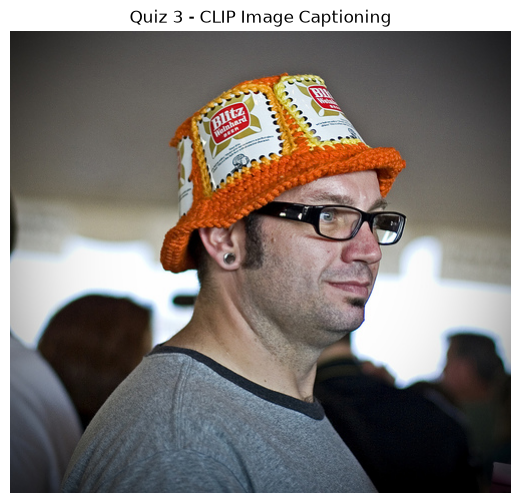

Generated Caption:
A man in a red shirt is sitting in a chair.

Ground Truth Captions:
1. The man with pierced ears is wearing glasses and an orange hat.
2. A man with glasses is wearing a beer can crocheted hat.
3. A man with gauges and glasses is wearing a Blitz hat.
4. A man in an orange hat starring at something.
5. A man wears an orange hat and glasses.


In [14]:

# ========================================
# Quiz 3 - Cell 12: Caption Generation
# ========================================

import torch
import zipfile
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# 1. 載入最佳模型
checkpoint = torch.load(
    QUIZ3_BEST_PATH,
    map_location=device,
    weights_only=False
)

caption_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=False
)

caption_model.eval()
caption_model.clip_encoder.eval()

print("Loaded Best Model")
print("Best Epoch:", checkpoint["epoch"])
print("Validation Loss:", checkpoint["val_loss"])


# 2. Greedy Decoding
@torch.no_grad()
def generate_caption(image, max_length=40):

    # CLIP 圖片前處理
    image_inputs = clip_processor(
        images=image,
        return_tensors="pt"
    )

    pixels = image_inputs["pixel_values"].to(device)

    # 從 BOS 開始
    generated_ids = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long,
        device=device
    )

    # 一次生成一個 Token
    for step in range(max_length - 1):

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            logits = caption_model(
                pixel_values=pixels,
                input_ids=generated_ids
            )

        # 取最後一個位置的預測
        next_token = logits[:, -1, :].argmax(
            dim=-1,
            keepdim=True
        )

        # EOS：停止生成
        if next_token.item() == EOS_ID:
            break

        generated_ids = torch.cat(
            [generated_ids, next_token],
            dim=1
        )

    # 去掉 BOS，轉回文字
    caption = caption_tokenizer.decode(
        generated_ids[0, 1:].tolist(),
        skip_special_tokens=True
    )

    return caption.strip()


# 3. 選取測試集第一張圖片
test_row = caption_test_df.iloc[0]

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    image_bytes = zf.read(
        "flickr30k-images/" + test_row["filename"]
    )

test_image = Image.open(
    BytesIO(image_bytes)
).convert("RGB")


# 4. 產生 Caption
predicted_caption = generate_caption(test_image)

# 5. 顯示圖片與結果
plt.figure(figsize=(8, 6))
plt.imshow(test_image)
plt.axis("off")
plt.title("Quiz 3 - CLIP Image Captioning")
plt.show()

print("Generated Caption:")
print(predicted_caption)

print("\nGround Truth Captions:")
for i, caption in enumerate(test_row["captions"], 1):
    print(f"{i}. {caption}")



========== Image 1 ==========
Generated: A man in a white hat is riding a cart with a white hat.
Ground Truth: Two men sitting on a cart being drawn by a horse down a cobblestone street.

========== Image 2 ==========
Generated: A woman in a colorful dress is sitting on a chair.
Ground Truth: A Chinese + man and younger boy in some type of worship place worshiping.

========== Image 3 ==========
Generated: A woman in a purple shirt is working on a piece of paper.
Ground Truth: A woman wearing a pink sweater and eyeglasses is wiping a wooden table with a pink sponge.

========== Image 4 ==========
Generated: A man in a black shirt is holding a camera.
Ground Truth: A middle-aged man with a backpack playfully pretends to box with younger child who does not look phased.

========== Image 5 ==========
Generated: A white dog is jumping over a white dog.
Ground Truth: The two dogs, one of which is leaping in the air, are chasing a ball outdoors.


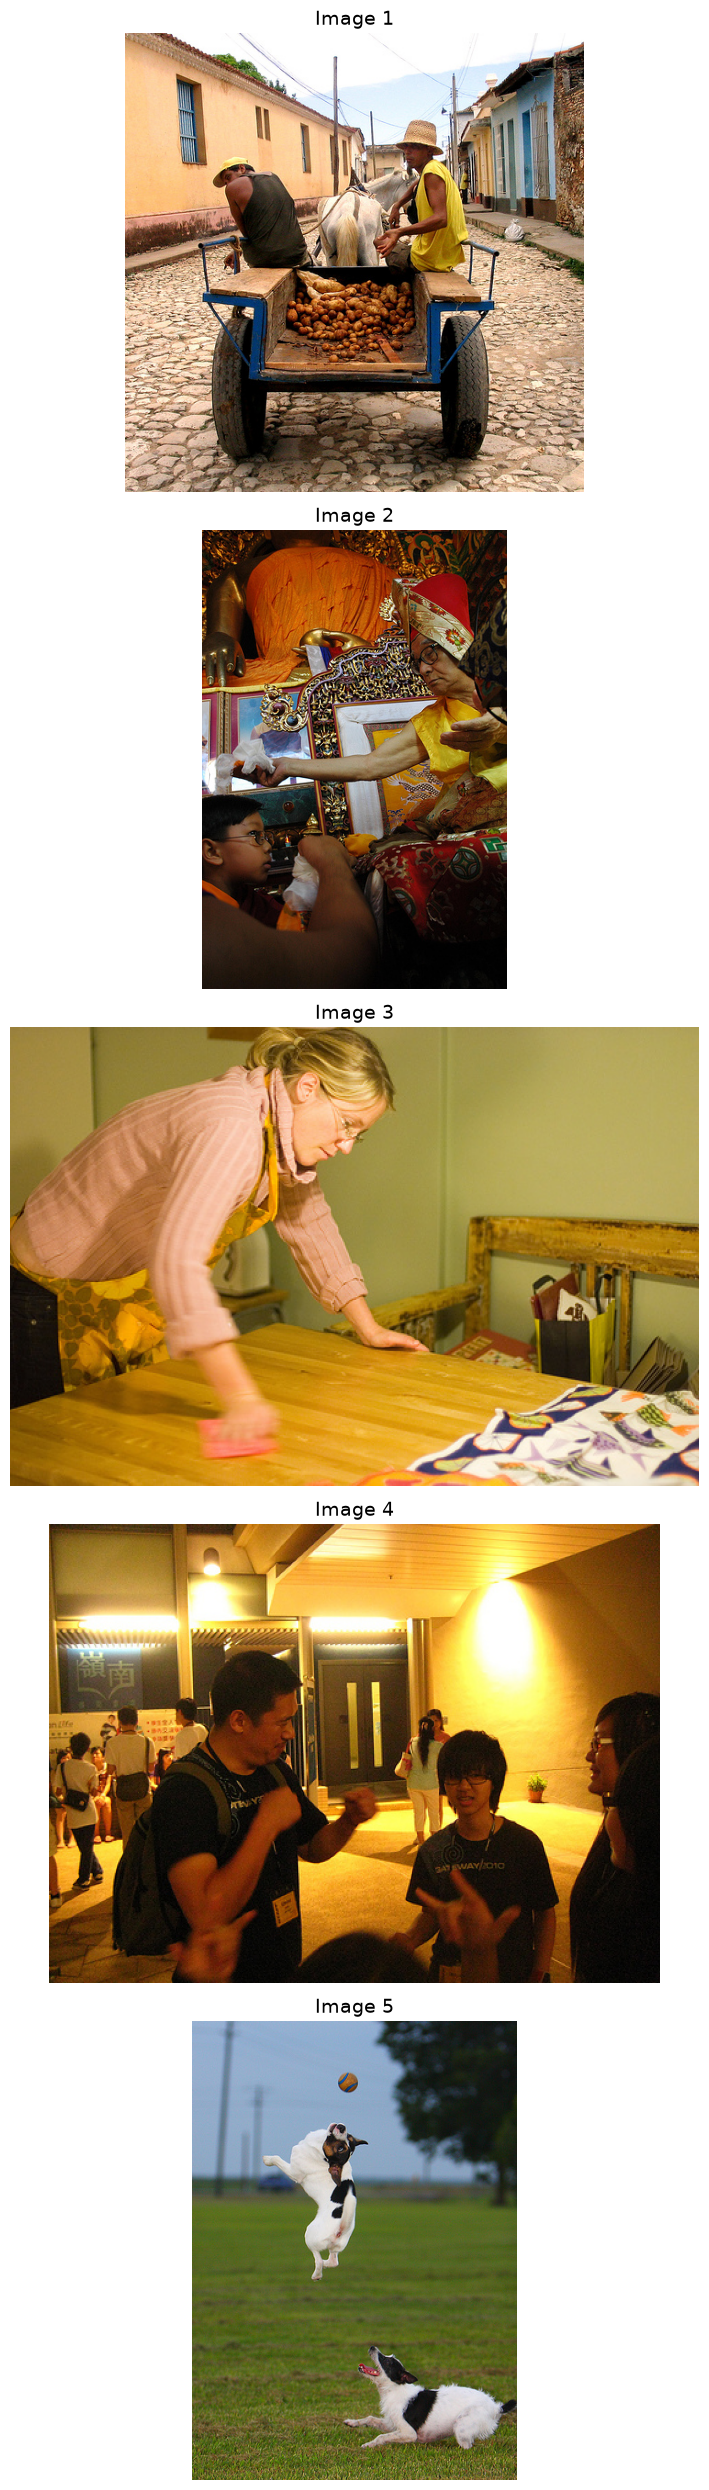


Multiple Image Inference Completed!


In [15]:

# ========================================
# Quiz 3 - Cell 13: Multiple Image Inference
# ========================================

import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import zipfile
import random

# 固定抽樣，方便重現結果
random.seed(42)

sample_indices = random.sample(
    range(len(caption_test_df)),
    5
)

fig, axes = plt.subplots(
    5, 1,
    figsize=(10, 25)
)

quiz3_sample_results = []

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    for i, idx in enumerate(sample_indices):

        row = caption_test_df.iloc[idx]

        image_bytes = zf.read(
            "flickr30k-images/" + row["filename"]
        )

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # 模型生成 Caption
        prediction = generate_caption(image)

        # Ground Truth
        ground_truth = row["captions"][0]

        quiz3_sample_results.append({
            "filename": row["filename"],
            "prediction": prediction,
            "ground_truth": ground_truth
        })

        axes[i].imshow(image)
        axes[i].axis("off")
        axes[i].set_title(
            f"Image {i+1}",
            fontsize=14
        )

        print(f"\n========== Image {i+1} ==========")
        print("Generated:", prediction)
        print("Ground Truth:", ground_truth)

plt.tight_layout()
plt.show()

print("\nMultiple Image Inference Completed!")


In [16]:

# ========================================
# Quiz 3 - Cell 14: BLEU Evaluation Setup
# ========================================

import sys
import subprocess
import importlib.util

# 1. 確認 NLTK 已安裝
if importlib.util.find_spec("nltk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "nltk"
    ])

from nltk.translate.bleu_score import (
    corpus_bleu,
    SmoothingFunction
)

# 2. BLEU Tokenizer
# 統一小寫、去除標點符號
import re

def bleu_tokenize(text):
    return re.findall(
        r"\w+",
        text.lower()
    )

# 3. 建立 BLEU 評估函式
def calculate_bleu(predictions, references):

    # predictions:
    # ["A dog is running", ...]

    # references:
    # [["A dog runs", "A dog is playing", ...], ...]

    pred_tokens = [
        bleu_tokenize(p)
        for p in predictions
    ]

    ref_tokens = [
        [bleu_tokenize(r) for r in refs]
        for refs in references
    ]

    smoothing = SmoothingFunction().method1

    scores = {}

    for n in range(1, 5):

        weights = tuple(
            [1.0 / n] * n
            + [0.0] * (4 - n)
        )

        score = corpus_bleu(
            ref_tokens,
            pred_tokens,
            weights=weights,
            smoothing_function=smoothing
        )

        scores[f"BLEU-{n}"] = score * 100

    return scores


# 4. 使用剛才的 5 張圖片測試
test_predictions = [
    item["prediction"]
    for item in quiz3_sample_results
]

test_references = [
    caption_test_df.loc[
        caption_test_df["filename"] == item["filename"],
        "captions"
    ].iloc[0]
    for item in quiz3_sample_results
]

test_bleu = calculate_bleu(
    test_predictions,
    test_references
)

print("BLEU Test (5 Images):")

for name, score in test_bleu.items():
    print(f"{name}: {score:.2f}")

print("\nBLEU Evaluation Function Ready!")


BLEU Test (5 Images):
BLEU-1: 49.99
BLEU-2: 33.67
BLEU-3: 22.80
BLEU-4: 16.98

BLEU Evaluation Function Ready!


In [17]:

# ========================================
# Quiz 3 - Cell 15: Full Test BLEU Evaluation
# ========================================

import json
import time
import zipfile
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

caption_model.eval()
caption_model.clip_encoder.eval()

quiz3_test_predictions = []
quiz3_test_references = []
quiz3_test_records = []

start_time = time.time()

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    for idx in tqdm(
        range(len(caption_test_df)),
        desc="Quiz 3 Test Inference"
    ):

        row = caption_test_df.iloc[idx]

        # 1. 讀取圖片
        image_bytes = zf.read(
            "flickr30k-images/" + row["filename"]
        )

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # 2. 生成 Caption
        prediction = generate_caption(image)

        # 3. 五句 Ground Truth
        references = list(row["captions"])

        quiz3_test_predictions.append(prediction)
        quiz3_test_references.append(references)

        quiz3_test_records.append({
            "filename": row["filename"],
            "prediction": prediction,
            "references": references
        })


# ========================================
# 計算 BLEU
# ========================================

quiz3_bleu_scores = calculate_bleu(
    quiz3_test_predictions,
    quiz3_test_references
)

elapsed = time.time() - start_time

print("\n===== Quiz 3 Test BLEU =====")

for name, score in quiz3_bleu_scores.items():
    print(f"{name}: {score:.2f}")

print(f"\nTotal Images: {len(quiz3_test_predictions)}")
print(f"Inference Time: {elapsed / 60:.2f} minutes")


# ========================================
# 儲存結果
# ========================================

results_path = (
    QUIZ3_SAVE_DIR / "quiz3_test_predictions.json"
)

with open(
    results_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        quiz3_test_records,
        f,
        ensure_ascii=False,
        indent=2
    )

bleu_path = (
    QUIZ3_SAVE_DIR / "quiz3_bleu_scores.json"
)

with open(
    bleu_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        quiz3_bleu_scores,
        f,
        indent=2
    )

print("\nPredictions Saved:", results_path)
print("BLEU Scores Saved:", bleu_path)

print("\nFull BLEU Evaluation Completed!")


Quiz 3 Test Inference:   0%|          | 0/1000 [00:00<?, ?it/s]


===== Quiz 3 Test BLEU =====
BLEU-1: 68.35
BLEU-2: 50.07
BLEU-3: 35.77
BLEU-4: 25.33

Total Images: 1000
Inference Time: 2.90 minutes

Predictions Saved: D:\project\MMIP\week5\quiz3_saved\quiz3_test_predictions.json
BLEU Scores Saved: D:\project\MMIP\week5\quiz3_saved\quiz3_bleu_scores.json

Full BLEU Evaluation Completed!


In [18]:

# ========================================
# Quiz 3 - Cell 16: BERTScore Setup
# ========================================

import sys
import subprocess
import importlib.util

# 1. 安裝 BERTScore（如果尚未安裝）
if importlib.util.find_spec("bert_score") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "bert-score"
    ])

from bert_score import score
import torch
import numpy as np
import time
import json

# 2. 準備資料
# 每張圖片有 1 句預測 + 5 句 Ground Truth
all_candidates = []
all_references = []

for prediction, references in zip(
    quiz3_test_predictions,
    quiz3_test_references
):
    for reference in references:
        all_candidates.append(prediction)
        all_references.append(reference)

print("Images:", len(quiz3_test_predictions))
print("Caption Pairs:", len(all_candidates))

# 3. 計算 BERTScore
start_time = time.time()

P, R, F1 = score(
    all_candidates,
    all_references,
    model_type="distilbert-base-uncased",
    lang="en",
    device=str(device),
    batch_size=32,
    verbose=True,
    rescale_with_baseline=False
)

# 4. 每張圖片取五句參考描述中最高的分數
P = P.numpy().reshape(-1, 5)
R = R.numpy().reshape(-1, 5)
F1 = F1.numpy().reshape(-1, 5)

best_idx = F1.argmax(axis=1)
rows = np.arange(len(F1))

quiz3_bertscore = {
    "Precision": float(P[rows, best_idx].mean()),
    "Recall": float(R[rows, best_idx].mean()),
    "F1": float(F1[rows, best_idx].mean())
}

elapsed = time.time() - start_time

print("\n===== Quiz 3 BERTScore =====")
for name, value in quiz3_bertscore.items():
    print(f"{name}: {value:.4f}")

print(f"\nEvaluation Time: {elapsed / 60:.2f} minutes")

# 5. 儲存評估結果
bertscore_path = (
    QUIZ3_SAVE_DIR / "quiz3_bertscore.json"
)

with open(
    bertscore_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "model_type": "distilbert-base-uncased",
            "reference_strategy": "best_of_5_by_F1",
            "rescale_with_baseline": False,
            "scores": quiz3_bertscore
        },
        f,
        indent=2
    )

print("\nBERTScore Saved:", bertscore_path)
print("BERTScore Evaluation Completed!")



Images: 1000
Caption Pairs: 5000
calculating scores...
computing bert embedding.


  0%|          | 0/185 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/157 [00:00<?, ?it/s]

done in 5.69 seconds, 879.31 sentences/sec

===== Quiz 3 BERTScore =====
Precision: 0.8712
Recall: 0.8576
F1: 0.8639

Evaluation Time: 0.12 minutes

BERTScore Saved: D:\project\MMIP\week5\quiz3_saved\quiz3_bertscore.json
BERTScore Evaluation Completed!


In [24]:

# ========================================
# Quiz 3 - Cell 21: Load Fine-tuned BLIP
# ========================================

import torch
import gc

from transformers import (
    BlipProcessor,
    BlipForConditionalGeneration
)

# 1. 將 Week 5 模型移到 CPU
caption_model.to("cpu")
clip_model.to("cpu")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU Memory Cleared!")

# 2. 載入 BLIP Processor
BLIP_MODEL_NAME = "Salesforce/blip-image-captioning-base"

week4_blip_processor = BlipProcessor.from_pretrained(
    BLIP_MODEL_NAME
)

# 3. 載入預訓練 BLIP 架構
week4_blip_model = (
    BlipForConditionalGeneration.from_pretrained(
        BLIP_MODEL_NAME
    )
)

# 4. 載入 Week 4 Fine-tuned 權重
checkpoint = torch.load(
    blip_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

week4_blip_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# 5. 移動到 GPU
week4_blip_model = week4_blip_model.to(device)
week4_blip_model.eval()

print("\nFine-tuned BLIP Loaded Successfully!")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Best Val Loss:", checkpoint["best_val_loss"])
print("Device:", next(week4_blip_model.parameters()).device)

if torch.cuda.is_available():
    print(
        "GPU Memory Allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )


GPU Memory Cleared!

Fine-tuned BLIP Loaded Successfully!
Checkpoint Epoch: 3
Best Val Loss: 2.1316538959800373
Device: cuda:0
GPU Memory Allocated: 1.17 GB


In [25]:

# ========================================
# Quiz 3 - Cell 22: BLIP Test Evaluation
# ========================================

import torch
import json
import time
import zipfile

from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

week4_blip_model.eval()

blip_predictions = []
blip_references = []
blip_records = []

start_time = time.time()

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    for idx in tqdm(
        range(len(caption_test_df)),
        desc="Week 4 BLIP Inference"
    ):

        row = caption_test_df.iloc[idx]

        # 1. 讀取與 Week 5 相同的圖片
        image_bytes = zf.read(
            "flickr30k-images/" + row["filename"]
        )

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        # 2. BLIP 影像前處理
        inputs = week4_blip_processor(
            images=image,
            return_tensors="pt"
        ).to(device)

        # 3. 生成 Caption
        with torch.inference_mode():

            generated_ids = week4_blip_model.generate(
                **inputs,
                max_new_tokens=40,
                num_beams=1,
                do_sample=False
            )

        prediction = (
            week4_blip_processor
            .batch_decode(
                generated_ids,
                skip_special_tokens=True
            )[0]
            .strip()
        )

        # 4. 五句 Ground Truth
        references = list(row["captions"])

        blip_predictions.append(prediction)
        blip_references.append(references)

        blip_records.append({
            "filename": row["filename"],
            "prediction": prediction,
            "references": references
        })

# ========================================
# 計算 BLEU
# ========================================

blip_bleu_scores = calculate_bleu(
    blip_predictions,
    blip_references
)

elapsed = time.time() - start_time

print("\n===== Week 4 Fine-tuned BLIP BLEU =====")

for name, score in blip_bleu_scores.items():
    print(f"{name}: {score:.2f}")

print("\nTotal Images:", len(blip_predictions))
print(f"Inference Time: {elapsed / 60:.2f} minutes")

# ========================================
# 儲存結果
# ========================================

blip_predictions_path = (
    QUIZ3_SAVE_DIR / "week4_blip_test_predictions.json"
)

with open(
    blip_predictions_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        blip_records,
        f,
        ensure_ascii=False,
        indent=2
    )

blip_bleu_path = (
    QUIZ3_SAVE_DIR / "week4_blip_bleu_scores.json"
)

with open(
    blip_bleu_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        blip_bleu_scores,
        f,
        indent=2
    )

print("\nPredictions Saved:", blip_predictions_path)
print("BLEU Scores Saved:", blip_bleu_path)
print("\nBLIP Evaluation Completed!")


Week 4 BLIP Inference:   0%|          | 0/1000 [00:00<?, ?it/s]


===== Week 4 Fine-tuned BLIP BLEU =====
BLEU-1: 74.84
BLEU-2: 57.80
BLEU-3: 43.67
BLEU-4: 32.91

Total Images: 1000
Inference Time: 3.96 minutes

Predictions Saved: D:\project\MMIP\week5\quiz3_saved\week4_blip_test_predictions.json
BLEU Scores Saved: D:\project\MMIP\week5\quiz3_saved\week4_blip_bleu_scores.json

BLIP Evaluation Completed!


In [26]:

# ========================================
# Quiz 3 - Cell 23: BLIP BERTScore
# ========================================

from bert_score import score
import numpy as np
import json
import time

# 1. 準備 5000 組 Caption 配對
blip_candidates = []
blip_all_references = []

for prediction, references in zip(
    blip_predictions,
    blip_references
):
    for reference in references:
        blip_candidates.append(prediction)
        blip_all_references.append(reference)

print("Images:", len(blip_predictions))
print("Caption Pairs:", len(blip_candidates))

# 2. 計算 BERTScore
start_time = time.time()

P, R, F1 = score(
    blip_candidates,
    blip_all_references,
    model_type="distilbert-base-uncased",
    lang="en",
    device=str(device),
    batch_size=32,
    verbose=True,
    rescale_with_baseline=False
)

# 3. 每張圖片取 F1 最高的參考描述
P = P.numpy().reshape(-1, 5)
R = R.numpy().reshape(-1, 5)
F1 = F1.numpy().reshape(-1, 5)

best_idx = F1.argmax(axis=1)
rows = np.arange(len(F1))

blip_bertscore = {
    "Precision": float(P[rows, best_idx].mean()),
    "Recall": float(R[rows, best_idx].mean()),
    "F1": float(F1[rows, best_idx].mean())
}

elapsed = time.time() - start_time

print("\n===== Week 4 BLIP BERTScore =====")

for name, value in blip_bertscore.items():
    print(f"{name}: {value:.4f}")

print(f"\nEvaluation Time: {elapsed:.2f} seconds")

# 4. 儲存結果
blip_bertscore_path = (
    QUIZ3_SAVE_DIR / "week4_blip_bertscore.json"
)

with open(
    blip_bertscore_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "model_type": "distilbert-base-uncased",
            "reference_strategy": "best_of_5_by_F1",
            "rescale_with_baseline": False,
            "scores": blip_bertscore
        },
        f,
        indent=2
    )

print("\nBERTScore Saved:", blip_bertscore_path)
print("BLIP BERTScore Evaluation Completed!")


Images: 1000
Caption Pairs: 5000
calculating scores...
computing bert embedding.


  0%|          | 0/187 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/157 [00:00<?, ?it/s]

done in 5.64 seconds, 886.15 sentences/sec

===== Week 4 BLIP BERTScore =====
Precision: 0.8893
Recall: 0.8741
F1: 0.8812

Evaluation Time: 6.73 seconds

BERTScore Saved: D:\project\MMIP\week5\quiz3_saved\week4_blip_bertscore.json
BLIP BERTScore Evaluation Completed!


,Model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,BERTScore F1
0,Week 4 Fine-tuned BLIP,74.8369,57.8038,43.6746,32.9053,0.8812
1,Week 5 CLIP + Transformer Decoder,68.3480,50.0735,35.7669,25.3337,0.8639


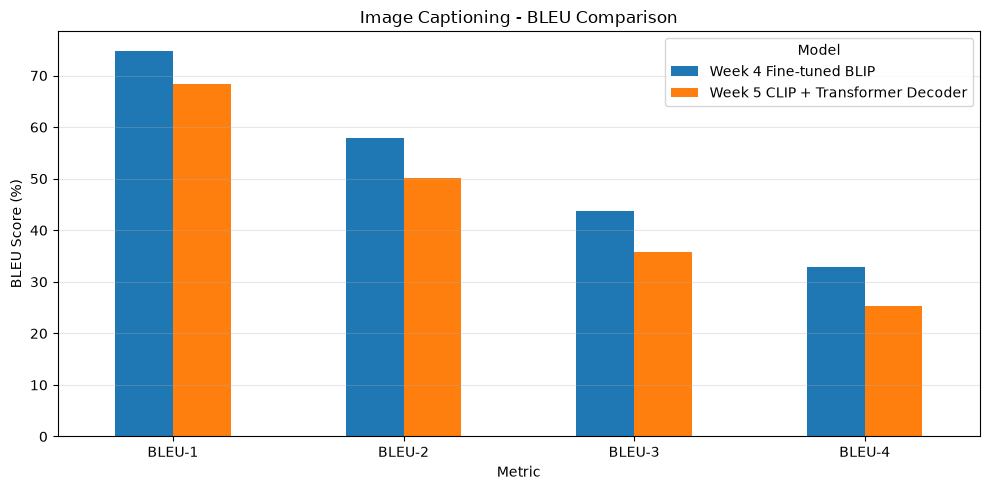

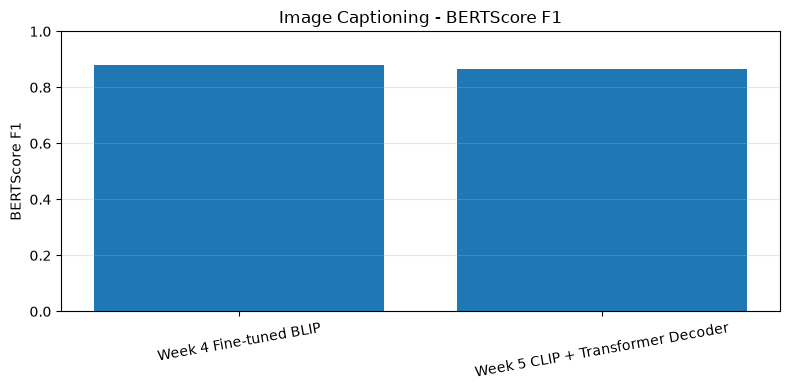


Saved Files:
D:\project\MMIP\week5\quiz3_saved\caption_model_comparison.csv
D:\project\MMIP\week5\quiz3_saved\caption_bleu_comparison.png
D:\project\MMIP\week5\quiz3_saved\caption_bertscore_comparison.png

Comparison Completed!


In [27]:

# ========================================
# Quiz 3 - Cell 24: Model Comparison
# ========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. 建立比較表
comparison_df = pd.DataFrame({
    "Model": [
        "Week 4 Fine-tuned BLIP",
        "Week 5 CLIP + Transformer Decoder"
    ],
    "BLEU-1": [
        blip_bleu_scores["BLEU-1"],
        quiz3_bleu_scores["BLEU-1"]
    ],
    "BLEU-2": [
        blip_bleu_scores["BLEU-2"],
        quiz3_bleu_scores["BLEU-2"]
    ],
    "BLEU-3": [
        blip_bleu_scores["BLEU-3"],
        quiz3_bleu_scores["BLEU-3"]
    ],
    "BLEU-4": [
        blip_bleu_scores["BLEU-4"],
        quiz3_bleu_scores["BLEU-4"]
    ],
    "BERTScore F1": [
        blip_bertscore["F1"],
        quiz3_bertscore["F1"]
    ]
})

display(comparison_df.round(4))

# 2. 儲存 CSV
comparison_path = (
    QUIZ3_SAVE_DIR / "caption_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

# 3. BLEU 比較圖
bleu_columns = [
    "BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"
]

ax = (
    comparison_df
    .set_index("Model")[bleu_columns]
    .T
    .plot(kind="bar", figsize=(10, 5), rot=0)
)

ax.set_title("Image Captioning - BLEU Comparison")
ax.set_ylabel("BLEU Score (%)")
ax.set_xlabel("Metric")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

bleu_chart_path = (
    QUIZ3_SAVE_DIR / "caption_bleu_comparison.png"
)

plt.savefig(bleu_chart_path, dpi=200)
plt.show()

# 4. BERTScore F1 比較圖
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    comparison_df["Model"],
    comparison_df["BERTScore F1"]
)

ax.set_title("Image Captioning - BERTScore F1")
ax.set_ylabel("BERTScore F1")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=10)
plt.tight_layout()

bert_chart_path = (
    QUIZ3_SAVE_DIR / "caption_bertscore_comparison.png"
)

plt.savefig(bert_chart_path, dpi=200)
plt.show()

print("\nSaved Files:")
print(comparison_path)
print(bleu_chart_path)
print(bert_chart_path)
print("\nComparison Completed!")


## Quiz 3 — 實驗結果與討論（Experimental Results and Discussion）

### 1. 實驗設定（Experimental Setup）

本實驗使用 Flickr30k 資料集進行影像描述生成（Image Captioning），並比較兩種不同模型的表現：

- **Week 4 — Fine-tuned BLIP：** 使用預訓練的 BLIP Image Captioning 模型，並進行 3 個 Epoch 的 Fine-tuning。
- **Week 5 — CLIP + Transformer Decoder：** 使用預訓練 CLIP Vision Transformer 作為影像編碼器（Image Encoder），凍結其參數，再搭配可訓練的 Transformer Decoder 生成影像描述，共訓練 5 個 Epoch。

兩種模型皆使用 Flickr30k 測試集中的 **1,000 張圖片**進行評估，每張圖片具有 5 句參考描述（Ground Truth Captions）。

為了確保比較的一致性，兩個模型使用相同的測試圖片，以及相同的 BLEU 和 BERTScore 計算方式。

### 2. 定量評估（Quantitative Evaluation）

| 評估指標 | Fine-tuned BLIP | CLIP + Transformer Decoder |
|---|---:|---:|
| BLEU-1 | **74.84** | 68.35 |
| BLEU-2 | **57.80** | 50.07 |
| BLEU-3 | **43.67** | 35.77 |
| BLEU-4 | **32.91** | 25.33 |
|